# Camera-ready run, version 2

Same experiment as `camera_ready_colab.ipynb`. Training, rules, thresholds, and the baseline are unchanged.

This copy prints three replies to the Stage 2 review comment:

1. The Stage 1 loss and the Stage 2 loss, as implemented.
2. Which labels each stage uses.
3. Test and validation metrics after Stage 1 alone, beside the same metrics after Stage 2.

Each stage keeps its own validation threshold. `SELECTED_THRESHOLD` remains the Stage 2 threshold used by the rest of the notebook.

Saved tables are printed in the cell output as well as written to disk.


# Camera-ready run

Upload this one notebook and run all cells, the same way as `cbis-ddsm-deepproblog-pipeline.ipynb`.

The trained program is the submitted three-rule program. This run also saves:

- stage-1 probabilities, scored before DeepProbLog fine-tuning
- stage-2 probabilities, scored after fine-tuning
- a ground-truth concept check of the submitted rules and of a revised margin map
- test metrics for the four concept heads
- a paired DeLong test against the pure ResNet18 baseline

The decision score is always the DeepProbLog query probability. The largest rule body is printed only as an explanation.

If the CSVs and `jpeg` folder are not on Kaggle, put them in `/content/data`.

# CBIS-DDSM → DeepProbLog

This notebook is the full pipeline: **prepare the CSVs**, **load mammogram JPEGs**, **augment the training images**, **search hyperparameters**, **train DeepProbLog**, then **evaluate and show images**.

## Goal of DeepProbLog

A plain CNN maps pixels straight to `malignant` / `benign`. You get a score, but not a reason.

DeepProbLog is **neuro-symbolic**:

1. Small neural nets look at the image and predict **concepts** a radiologist would name: lesion kind (mass vs calcification), mass shape, mass margin, and calcification type.
2. A **Prolog program** turns those uncertain concept probabilities into a diagnosis with explicit rules, for example:
   - a **mass** is called malignant if the shape is irregular or the margin is spiculated
   - a **calcification** is called malignant if the type is suspicious
3. Training updates the neural nets so both the concepts and the final `malignant(X)` query match the labels.

The point is not only accuracy. It is to keep the decision in a form you can inspect: if `P(malignant)` is high, the traces show *which* concept fired.

## Steps in this notebook

| Step | What happens |
|---|---|
| 1–3 | Install, import, set config |
| 4–6 | Load CSVs, merge mass+calc, remove patient leakage, save splits |
| 7 | Map CSV text to Prolog concept symbols |
| 8 | Load JPEGs and show train / val / test images |
| 8b | **Augment training images only** (flips, small rotations) to grow the train set |
| 9 | Define the concept CNNs and DeepProbLog datasets |
| 10 | **Grid-search** learning rate and batch size on validation F1, then train the final model |
| 11 | Metrics, reasoning traces, predicted test images |
| 12 | Save weights and metrics |

## Kaggle setup

- Attach dataset: `cbis-ddsm-breast-cancer-image-dataset`
- Accelerator: GPU T4 (P100 is not compatible with this PyTorch build)
- First check: `SMOKE_TEST = True` (tiny sample, fast wiring test)
- Full run: `SMOKE_TEST = False`
- `RUN_GRID_SEARCH = True` tries a few `(lr, batch)` pairs with fewer epochs, then retrains with the best pair

## How to read the log

- `DEVICE: cuda` means the GPU is in use.
- `loaded N tensors (0 synthetic)` means real JPEGs were found. If synthetic is not 0, the images are placeholders and the run is only a smoke test.

The Prolog rules are a computational working program, not official BI-RADS criteria.

**Next run (accuracy):** set `BACKBONE=resnet18`, `CONCEPT_WARMUP_EPOCHS=8`, upload to Kaggle **T4**, delete old `checkpoints/final_model_checkpoint_*.pt` if present, then Run All. Expect warm-up (~10–20 min) + DeepProbLog (~3 h). Check dual DPL operating points and baseline threshold table in the metrics / baseline cells.


## 1) Install packages

**What:** install DeepProbLog, scikit-learn, pandas, and Pillow in this kernel.

**Why:** Kaggle runtimes do not always include DeepProbLog. This cell is safe to re-run.


In [1]:
%pip install -q deepproblog scikit-learn pandas pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.2/131.2 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 535.4/535.4 kB 24.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


## 2) Imports

**What:** load libraries for tables, images, PyTorch, and plots.

**Why:** later cells need pandas for CSVs, matplotlib to show mammograms, and torch for the concept networks.


In [2]:
import json
import os
import random
from datetime import datetime, timezone
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from torchvision import models, transforms
from torchvision.models import ResNet18_Weights

print("pandas:", pd.__version__)
print("torch:", torch.__version__, "| cuda:", torch.cuda.is_available())

pandas: 2.3.3
torch: 2.10.0+cu128 | cuda: True


## 3) Config

**What:** one settings cell for the whole notebook.

**Why:** change smoke-test size, training length, augmentation, and the hyperparameter grid here.

- `SMOKE_TEST=True` — tiny wiring test (few patients, 1 epoch).
- `SMOKE_TEST=False` — full split and 15 epochs.
- `N_AUGMENT` — extra random views per **training** image only. Validation and test stay clean.
- `BACKBONE` — `resnet18` (ImageNet transfer) or `tiny` (from-scratch CNN for smoke tests).
- `CONCEPT_WARMUP_EPOCHS` — supervised CE on CSV concepts before DeepProbLog (0 = skip).
- `FREEZE_BACKBONE_EPOCHS` — train concept heads only, then unfreeze the ResNet trunk at a lower LR.
- `RUN_NEURAL_BASELINE` — train a pure ResNet18 malignant/benign classifier on the same splits (no DeepProbLog).
- `PATCH_MODE` — `resize` / `center` / `random`: how the ROI crop becomes a fixed `IMAGE_SIZE` patch (see section 8).
- `BALANCE_CLASSES=True` — malignant training rows get extra augmented copies until both classes are equal in size.
- `THRESHOLD_MODE` / `TARGET_SENSITIVITY` — how the decision threshold on `P(malignant)` is chosen on validation. `0.5` under-calls malignant; `target_sensitivity` lowers it until validation recall reaches the target.
- `RUN_GRID_SEARCH=True` — try each `(lr, batch_size)` for `SEARCH_EPOCHS`, pick the best validation macro F1, then retrain with `EPOCHS`.
- `USE_SYNTHETIC_IF_MISSING=False` — missing JPEGs must raise an error.
- `FORCE_CPU=False` — use T4 if the CUDA probe succeeds.


In [3]:
# ===================== ONE CONFIG FOR EVERYTHING =====================
SMOKE_TEST = False                 # True = tiny wiring test; False = full run
SMOKE_N_PATIENTS = 20             # patients per official split (data prep)
SMOKE_N_SAMPLES = 24              # max rows used for DeepProbLog tensors
VAL_SIZE = 0.15
RANDOM_SEED = 42
# Patient split uses SPLIT_SEED only. Training seeds must not move patients.
SPLIT_SEED = 42
# Run All trains RANDOM_SEED once. Extra seeds do not train unless you opt in.
EXTRA_TRAIN_SEEDS = []  # later: [7] or [7, 11]
RUN_EXTRA_SEEDS = False
BOOTSTRAP_N = 2000
BOOTSTRAP_SEED = 42

EPOCHS = 1 if SMOKE_TEST else 15         # full run: 15 epochs
BATCH_SIZE = 1 if SMOKE_TEST else 2      # default if grid search is off; drop to 2 on OOM
# Medical mammography: higher res keeps fine margin / spiculation detail.
# 224 is the next step (ImageNet-friendly); 256 is ok on T4 with batch=2.
# 512+ is usually too slow for DeepProbLog ExactEngine with 4 nets.
IMAGE_SIZE = 64 if SMOKE_TEST else 224
# How to turn a ROI crop into a fixed tensor (one patch per image — DeepProbLog-friendly):
#   "resize" = stretch whole crop to IMAGE_SIZE (old behaviour; can smear margins)
#   "center" = scale so the short side >= IMAGE_SIZE, then center-crop (val/test default)
#   "random" = RandomResizedCrop on train; center-crop on val/test (recommended)
PATCH_MODE = "resize" if SMOKE_TEST else "random"
# Perception backbone for the four DeepProbLog concept predicates.
#   "resnet18" — ImageNet-pretrained ResNet18 shared trunk + 4 heads (recommended)
#   "tiny"     — from-scratch 3-layer CNN (fast smoke / ablation)
BACKBONE = "tiny" if SMOKE_TEST else "resnet18"
FREEZE_BACKBONE_EPOCHS = 0 if SMOKE_TEST else 2   # DPL phase: unused if concept warm-up ran
BACKBONE_LR_MULT = 0.1                           # trunk LR = LR * this after unfreeze
# Supervised concept warm-up (CE on kind/shape/margin/calc) before DeepProbLog.
CONCEPT_WARMUP_EPOCHS = 1 if SMOKE_TEST else 8
CONCEPT_WARMUP_FREEZE_EPOCHS = 0 if SMOKE_TEST else 2  # freeze trunk for first N warm-up epochs
CONCEPT_WARMUP_BATCH = 4 if SMOKE_TEST else 16
RUN_NEURAL_BASELINE = not SMOKE_TEST             # pure ResNet18 mal/ben on same splits
BASELINE_EPOCHS = 1 if SMOKE_TEST else 15
LR = 0.0003                                # default if grid search is off
USE_SYNTHETIC_IF_MISSING = False  # missing JPEG must fail; do not invent images
FORCE_CPU = False                 # use GPU if the probe succeeds (T4). P100 still falls back to CPU.
SHOW_N_IMAGES = 8                 # pictures to draw in each image grid

# Train-only augmentation: each original train image is kept, plus N_AUGMENT random copies.
N_AUGMENT = 1 if SMOKE_TEST else 2

# Class balance. Malignant is ~41% of train, so at 0.5 the model under-calls malignant.
# With BALANCE_CLASSES=True the malignant rows get extra augmented copies until both
# classes have the same number of training images. Validation and test are untouched.
BALANCE_CLASSES = True

# Decision threshold on P(malignant). The threshold is chosen on VALIDATION only and
# then applied unchanged to TEST, so the test numbers stay honest.
#   "fixed"              -> use DECISION_THRESHOLD as is
#   "target_sensitivity" -> among validation thresholds with sensitivity >= TARGET_SENSITIVITY,
#                            keep the highest specificity. Ties keep the lowest threshold,
#                            because the sweep is ascending and idxmax returns the first row.
#   "youden"             -> maximize sensitivity + specificity - 1
#   "f1_macro"           -> maximize macro F1
THRESHOLD_MODE = "target_sensitivity"
TARGET_SENSITIVITY = 0.80
DECISION_THRESHOLD = 0.5

# Small grid on validation macro F1. Keep it small: DeepProbLog exact inference is slow.
RUN_GRID_SEARCH = True
SEARCH_EPOCHS = 1 if SMOKE_TEST else 3
GRID_LEARNING_RATES = [3e-4, 1e-3] if SMOKE_TEST else [3e-4, 1e-3, 3e-3]
GRID_BATCH_SIZES = [2] if SMOKE_TEST else [2, 4]

DATASET_HANDLE = "awsaf49/cbis-ddsm-breast-cancer-image-dataset"
KAGGLE_INPUT = Path("/kaggle/input/cbis-ddsm-breast-cancer-image-dataset")
KAGGLE_WORKING = Path("/kaggle/working")
LOCAL_DATA = Path("../data")

CSV_FILENAMES = {
    "mass_train": "mass_case_description_train_set.csv",
    "mass_test": "mass_case_description_test_set.csv",
    "calc_train": "calc_case_description_train_set.csv",
    "calc_test": "calc_case_description_test_set.csv",
}

PROGRAM_FALLBACK = """
nn(kind_net, [X], Y, [mass, calcification]) :: lesion_kind(X, Y).
nn(shape_net, [X], Y, [regular, irregular, unknown]) :: shape(X, Y).
nn(margin_net, [X], Y, [circumscribed, spiculated, other, unknown]) :: margin(X, Y).
nn(calc_net, [X], Y, [absent, typically_benign, suspicious]) :: calc(X, Y).

malignant(X) :- lesion_kind(X, mass), shape(X, irregular).
malignant(X) :- lesion_kind(X, mass), margin(X, spiculated).
malignant(X) :- lesion_kind(X, calcification), calc(X, suspicious).
""".strip()

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

def pick_device(force_cpu=False):
    """Prefer CUDA, but fall back to CPU if the binary can't run on this GPU.
    Common on Kaggle when PyTorch wheels don't match the accelerator arch.
    """
    if force_cpu or not torch.cuda.is_available():
        return torch.device("cpu")
    try:
        # Probe that kernels actually work on this GPU (not just "cuda available").
        x = torch.zeros(1, device="cuda")
        y = x + 1
        torch.cuda.synchronize()
        del x, y
        torch.cuda.empty_cache()
        return torch.device("cuda")
    except Exception as exc:
        print("CUDA probe failed → using CPU. Reason:", type(exc).__name__, str(exc)[:200])
        return torch.device("cpu")

DEVICE = pick_device(FORCE_CPU)
print("DEVICE:", DEVICE)
if DEVICE.type == "cpu" and torch.cuda.is_available():
    print("Note: CUDA is visible but unusable with this PyTorch build. DeepProbLog will run on CPU.")

if Path("/kaggle/working").is_dir():
    OUTPUT_DIR = Path("/kaggle/working/processed")
else:
    OUTPUT_DIR = Path("../notebooks/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if SMOKE_TEST:
    print("=" * 64)
    print("SMOKE_TEST=True — tiny wiring test on a small sample.")
    print("=" * 64)
print("OUTPUT_DIR:", OUTPUT_DIR.resolve())


DEVICE: cuda
OUTPUT_DIR: /kaggle/working/processed


## 4) Find the four CBIS CSVs

**What:** search Kaggle input, then local `data/`, for the official mass and calc description files.

**Why:** the files are not always at a fixed path. Walking the tree (skipping `jpeg/`) keeps this cell working on Kaggle and on a laptop.


In [4]:
def find_csv_paths(root, filenames):
    root = Path(root)
    found, remaining = {}, set(filenames.values())
    for dirpath, dirnames, files in os.walk(root):
        dirnames[:] = [d for d in dirnames if d.lower() != "jpeg"]
        for fname in files:
            if fname in remaining:
                key = next(k for k, v in filenames.items() if v == fname)
                found[key] = Path(dirpath) / fname
                remaining.discard(fname)
        if not remaining:
            break
    missing = [k for k in filenames if k not in found]
    if missing:
        raise FileNotFoundError(f"Missing {missing} under {root}")
    return found


def resolve_data_root():
    if KAGGLE_INPUT.is_dir():
        return KAGGLE_INPUT, "kaggle_input"
    # other common Kaggle mount
    for p in Path("/kaggle/input").glob("*cbis*") if Path("/kaggle/input").is_dir() else []:
        if p.is_dir():
            return p, "kaggle_input_scan"
    if LOCAL_DATA.is_dir() and all((LOCAL_DATA / fn).exists() for fn in CSV_FILENAMES.values()):
        return LOCAL_DATA, "local_data"
    content_data = Path("/content/data")
    if content_data.is_dir() and all((content_data / fn).exists() for fn in CSV_FILENAMES.values()):
        return content_data, "colab_content_data"
    try:
        import kagglehub
        downloaded = Path(kagglehub.dataset_download(DATASET_HANDLE))
        return downloaded, "kagglehub_download"
    except Exception as exc:
        raise FileNotFoundError("No CBIS-DDSM data found") from exc


DATA_ROOT, DATA_SOURCE = resolve_data_root()
CSV_PATHS = find_csv_paths(DATA_ROOT, CSV_FILENAMES)
print(f"Data source: {DATA_SOURCE}\nRoot: {DATA_ROOT}")
for k, v in CSV_PATHS.items():
    print(f"  {k}: {v}")


Data source: kagglehub_download
Root: /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset
  calc_test: /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/csv/calc_case_description_test_set.csv
  calc_train: /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/csv/calc_case_description_train_set.csv
  mass_test: /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/csv/mass_case_description_test_set.csv
  mass_train: /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/csv/mass_case_description_train_set.csv


## 5) Merge mass+calc, fix leakage, split by patient

**What:** concatenate mass and calcification tables, assign overlapping patients entirely to train, then cut a patient-disjoint validation set.

**Why:** after merging, some patients appear in both official train and test. A patient-level split is required so the same woman is never in train and test.


In [5]:
STRING_COLUMNS = [
    "patient_id", "left or right breast", "image view", "abnormality type",
    "mass shape", "mass margins", "calc type", "calc distribution", "pathology",
    "image file path", "cropped image file path", "ROI mask file path",
]


def normalize_columns(df):
    out = df.copy()
    out.columns = [c.strip() for c in out.columns]
    if "breast density" in out.columns:
        out = out.rename(columns={"breast density": "breast_density"})
    for col in STRING_COLUMNS:
        if col in out.columns:
            out[col] = out[col].astype(str).str.strip().replace({"nan": np.nan, "None": np.nan, "": np.nan})
    return out


def add_meta(df, kind, official_split):
    out = df.copy()
    out["abnormality_kind"] = kind
    out["official_split"] = official_split
    return out


def sample_patients(df, n_patients, seed):
    patients = df["patient_id"].dropna().unique()
    if len(patients) <= n_patients:
        return df.copy()
    chosen = set(random.Random(seed).sample(list(patients), n_patients))
    return df[df["patient_id"].isin(chosen)].copy()


def resolve_cross_split_patient_leakage(train_df, test_df):
    """CBIS mass/calc official CSVs can place the same patient in train AND test
    (e.g. mass in train, calc in test). Keep ALL rows for those patients in train
    and drop them from test so splits stay patient-disjoint.
    """
    train_p = set(train_df["patient_id"].dropna())
    test_p = set(test_df["patient_id"].dropna())
    overlap = train_p & test_p
    if not overlap:
        print("No cross-split patient overlap.")
        return train_df, test_df

    print(f"Found {len(overlap)} patients in BOTH official train and test after merge.")
    print("  Assigning all their rows to TRAIN and removing them from TEST.")
    leaked_test_rows = test_df[test_df["patient_id"].isin(overlap)].copy()
    train_fixed = pd.concat([train_df, leaked_test_rows], ignore_index=True)
    test_fixed = test_df[~test_df["patient_id"].isin(overlap)].reset_index(drop=True)
    # drop duplicate rows if any exact duplicates appear
    train_fixed = train_fixed.drop_duplicates().reset_index(drop=True)
    return train_fixed, test_fixed


raw = {k: pd.read_csv(v) for k, v in CSV_PATHS.items()}
mass_train = add_meta(normalize_columns(raw["mass_train"]), "mass", "train")
mass_test = add_meta(normalize_columns(raw["mass_test"]), "mass", "test")
calc_train = add_meta(normalize_columns(raw["calc_train"]), "calcification", "train")
calc_test = add_meta(normalize_columns(raw["calc_test"]), "calcification", "test")

df_train_all = pd.concat([mass_train, calc_train], ignore_index=True)
df_test_all = pd.concat([mass_test, calc_test], ignore_index=True)
print("Official train:", len(df_train_all), "rows |", df_train_all["patient_id"].nunique(), "patients")
print("Official test: ", len(df_test_all), "rows |", df_test_all["patient_id"].nunique(), "patients")

df_train_all, df_test_all = resolve_cross_split_patient_leakage(df_train_all, df_test_all)
print("After leakage fix train:", len(df_train_all), "rows |", df_train_all["patient_id"].nunique(), "patients")
print("After leakage fix test: ", len(df_test_all), "rows |", df_test_all["patient_id"].nunique(), "patients")

if SMOKE_TEST:
    df_train_all = sample_patients(df_train_all, SMOKE_N_PATIENTS, SPLIT_SEED)
    df_test_all = sample_patients(df_test_all, SMOKE_N_PATIENTS, SPLIT_SEED + 1)
    print("After smoke sampling:", len(df_train_all), "train rows |", len(df_test_all), "test rows")

gss = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE, random_state=SPLIT_SEED)
tr_idx, va_idx = next(gss.split(df_train_all, groups=df_train_all["patient_id"]))
df_train = df_train_all.iloc[tr_idx].reset_index(drop=True)
df_val = df_train_all.iloc[va_idx].reset_index(drop=True)
df_test = df_test_all.reset_index(drop=True)

tr_p, va_p, te_p = set(df_train.patient_id), set(df_val.patient_id), set(df_test.patient_id)
print("overlap train∩val:", len(tr_p & va_p), "| train∩test:", len(tr_p & te_p), "| val∩test:", len(va_p & te_p))
assert tr_p.isdisjoint(va_p), "Train/val patient leakage"
assert tr_p.isdisjoint(te_p), "Train/test patient leakage"
assert va_p.isdisjoint(te_p), "Val/test patient leakage"
print("Leakage checks passed.")
for name, df in (("train", df_train), ("val", df_val), ("test", df_test)):
    print(f"{name:5s}: {len(df):>5} rows | {df['patient_id'].nunique():>4} patients")


Official train: 2864 rows | 1248 patients
Official test:  704 rows | 349 patients
Found 31 patients in BOTH official train and test after merge.
  Assigning all their rows to TRAIN and removing them from TEST.
After leakage fix train: 2924 rows | 1248 patients
After leakage fix test:  644 rows | 318 patients
overlap train∩val: 0 | train∩test: 0 | val∩test: 0
Leakage checks passed.
train:  2462 rows | 1060 patients
val  :   462 rows |  188 patients
test :   644 rows |  318 patients


## 6) Save the split tables

**What:** write `cbis_train.csv`, `cbis_val.csv`, `cbis_test.csv`, and a patient-to-split map.

**Why:** so you can inspect exactly which cases this run used.


In [6]:
# Save processed artifacts (same session will also train on these frames)
patient_splits = []
for split_name, frame in (("train", df_train), ("val", df_val), ("test", df_test)):
    for pid in sorted(frame["patient_id"].dropna().unique()):
        patient_splits.append({"patient_id": pid, "split": split_name})
pd.DataFrame(patient_splits).to_csv(OUTPUT_DIR / "cbis_patient_splits.csv", index=False)
df_train.to_csv(OUTPUT_DIR / "cbis_train.csv", index=False)
df_val.to_csv(OUTPUT_DIR / "cbis_val.csv", index=False)
df_test.to_csv(OUTPUT_DIR / "cbis_test.csv", index=False)

meta = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "smoke_test": SMOKE_TEST,
    "smoke_n_patients": SMOKE_N_PATIENTS if SMOKE_TEST else None,
    "val_size": VAL_SIZE,
    "random_seed": RANDOM_SEED,
    "split_seed": SPLIT_SEED,
    "data_source": DATA_SOURCE,
    "data_root": str(DATA_ROOT),
    "counts": {
        "train_rows": len(df_train),
        "val_rows": len(df_val),
        "test_rows": len(df_test),
        "train_patients": df_train["patient_id"].nunique(),
        "val_patients": df_val["patient_id"].nunique(),
        "test_patients": df_test["patient_id"].nunique(),
    },
}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(meta, indent=2))
print("Saved prep outputs to", OUTPUT_DIR.resolve())


Saved prep outputs to /kaggle/working/processed


## 7) Map CSV descriptors to concepts

**What:** convert `mass shape`, `mass margins`, `calc type`, and `abnormality_kind` into the symbols used in the Prolog program.

**Why:** DeepProbLog queries `shape(X, irregular)`, not the original CBIS strings. Any calcification is **not** treated as malignant; only suspicious types map to `suspicious`.


In [7]:
def tokenize_descriptor(value):
    if pd.isna(value):
        return []
    text = str(value).strip().upper()
    if text in {"", "NAN", "NONE"}:
        return []
    for sep in ("-", "/", "_", " "):
        text = text.replace(sep, " ")
    return [t for t in text.split() if t]


def map_shape(value):
    tokens = tokenize_descriptor(value)
    if not tokens:
        return "unknown"
    if any(t in {"IRREGULAR", "ARCHITECTURAL", "DISTORTION"} for t in tokens):
        return "irregular"
    if any(t in {"ROUND", "OVAL", "LOBULATED"} for t in tokens):
        return "regular"
    return "unknown"


def map_margin(value):
    tokens = tokenize_descriptor(value)
    if not tokens:
        return "unknown"
    if "SPICULATED" in tokens:
        return "spiculated"
    if "CIRCUMSCRIBED" in tokens:
        return "circumscribed"
    return "other"


def map_calc(row):
    # Any calcification present is NOT a malignancy label. Most CBIS calc cases are benign.
    if str(row.get("abnormality_kind", "")).lower() != "calcification":
        return "absent"
    tokens = tokenize_descriptor(row.get("calc type"))
    if any(t in {"PLEOMORPHIC", "AMORPHOUS"} for t in tokens) or (
        "FINE" in tokens and "LINEAR" in tokens
    ) or "BRANCHING" in tokens:
        return "suspicious"
    return "typically_benign"


def map_margin_revised(value):
    """Separate the suspicious margins that the submitted map puts in other.

    CBIS writes the BI-RADS indistinct margin as ILL_DEFINED.
    The most suspicious token wins. Obscured is kept and is not a malignancy rule.
    Training does not use this column.
    """
    tokens = tokenize_descriptor(value)
    if not tokens:
        return "unknown"
    if "SPICULATED" in tokens:
        return "spiculated"
    if "INDISTINCT" in tokens or ("ILL" in tokens and "DEFINED" in tokens):
        return "indistinct"
    if "MICROLOBULATED" in tokens:
        return "microlobulated"
    if "OBSCURED" in tokens:
        return "obscured"
    if "CIRCUMSCRIBED" in tokens:
        return "circumscribed"
    return "unknown"


def map_calc_revised(row):
    """Missing calcification type stays unknown. The submitted map calls it typically benign."""
    if str(row.get("abnormality_kind", "")).lower() != "calcification":
        return "absent"
    tokens = tokenize_descriptor(row.get("calc type"))
    if not tokens:
        return "unknown"
    if any(t in {"PLEOMORPHIC", "AMORPHOUS"} for t in tokens) or (
        "FINE" in tokens and "LINEAR" in tokens
    ) or "BRANCHING" in tokens:
        return "suspicious"
    return "typically_benign"


def add_concepts(df):
    out = df.copy()
    out["shape_concept"] = out["mass shape"].map(map_shape) if "mass shape" in out.columns else "unknown"
    out["margin_concept"] = out["mass margins"].map(map_margin) if "mass margins" in out.columns else "unknown"
    out["margin_concept_revised"] = out["mass margins"].map(map_margin_revised) if "mass margins" in out.columns else "unknown"
    out["calc_concept"] = out.apply(map_calc, axis=1)
    out["calc_concept_revised"] = out.apply(map_calc_revised, axis=1)
    out["kind_concept"] = out["abnormality_kind"].map(
        lambda x: "calcification" if str(x).strip().lower() == "calcification" else "mass"
    )
    out["malignant"] = out["pathology"].map(lambda x: 1.0 if str(x).strip().upper() == "MALIGNANT" else 0.0)
    return out


df_train = add_concepts(df_train)
df_val = add_concepts(df_val)
df_test = add_concepts(df_test)
display(df_train[["patient_id", "abnormality_kind", "shape_concept", "margin_concept", "calc_concept", "malignant"]].sample(10))
print("calc_concept counts:\n", df_train["calc_concept"].value_counts())
print("malignant rate train/val/test:",
      float(df_train["malignant"].mean()),
      float(df_val["malignant"].mean()),
      float(df_test["malignant"].mean()))


,patient_id,abnormality_kind,shape_concept,margin_concept,calc_concept,malignant
856,P_01485,mass,regular,other,absent,0.0
1620,P_00780,calcification,unknown,unknown,typically_benign,0.0
787,P_01357,mass,regular,spiculated,absent,1.0
2351,P_02220,calcification,unknown,unknown,suspicious,1.0
883,P_01543,mass,regular,other,absent,0.0
2357,P_02259,calcification,unknown,unknown,suspicious,1.0
1647,P_00809,calcification,unknown,unknown,suspicious,1.0
1942,P_01300,calcification,unknown,unknown,suspicious,1.0
1100,P_00007,calcification,unknown,unknown,suspicious,0.0
2113,P_01522,calcification,unknown,unknown,suspicious,0.0


calc_concept counts:
 calc_concept
absent              1124
suspicious           852
typically_benign     486
Name: count, dtype: int64
malignant rate train/val/test: 0.4138911454102356 0.3917748917748918 0.39906832298136646


## 7b) Rules on ground-truth concepts, and a controlled probability check

This cell does not use images. It asks ProbLog for `P(malignant)` from the recorded concepts.

The controlled example shows why the largest rule body is not the query probability: the mass rules share `lesion_kind`.

The test-set table compares the submitted rules with a revised margin map. The revised map lets indistinct (`ILL_DEFINED`) and microlobulated fire a mass rule. Obscured and circumscribed do not. The network is still trained with the submitted rules.


In [8]:
from problog import get_evaluatable
from problog.program import PrologString

CONTROLLED = """
0.80::lesion_kind(img, mass); 0.20::lesion_kind(img, calcification).
0.10::shape(img, regular); 0.70::shape(img, irregular); 0.20::shape(img, unknown).
0.20::margin(img, circumscribed); 0.40::margin(img, spiculated); 0.25::margin(img, other); 0.15::margin(img, unknown).
0.05::calc(img, absent); 0.10::calc(img, typically_benign); 0.85::calc(img, suspicious).
malignant(X) :- lesion_kind(X, mass), shape(X, irregular).
malignant(X) :- lesion_kind(X, mass), margin(X, spiculated).
malignant(X) :- lesion_kind(X, calcification), calc(X, suspicious).
query(malignant(img)).
"""
controlled = float(next(iter(get_evaluatable().create_from(PrologString(CONTROLLED)).evaluate().values())))
body_max = max(0.80 * 0.70, 0.80 * 0.40, 0.20 * 0.85)
shared = 0.80 * (0.70 + 0.30 * 0.40) + 0.20 * 0.85
print(f"Controlled query probability {controlled:.3f}")
print(f"Shared-atom probability    {shared:.3f}")
print(f"Largest rule body          {body_max:.3f}")
if abs(controlled - shared) > 1e-6:
    raise AssertionError("ProbLog query probability did not match the shared-atom formula.")
print("The decision uses the query probability, not the largest rule body.")


def _rule_program(frame, margin_col, calc_col, extra_margins):
    lines = ["% certain concept facts"]
    for i in range(len(frame)):
        row = frame.iloc[i]
        lines.append(f"lesion_kind(c{i}, {row['kind_concept']}).")
        lines.append(f"shape(c{i}, {row['shape_concept']}).")
        lines.append(f"margin(c{i}, {row[margin_col]}).")
        lines.append(f"calc(c{i}, {row[calc_col]}).")
    lines.append("malignant(X) :- lesion_kind(X, mass), shape(X, irregular).")
    for margin_name in extra_margins:
        lines.append(f"malignant(X) :- lesion_kind(X, mass), margin(X, {margin_name}).")
    lines.append("malignant(X) :- lesion_kind(X, calcification), calc(X, suspicious).")
    for i in range(len(frame)):
        lines.append(f"query(malignant(c{i})).")
    return "\n".join(lines) + "\n"


def rule_probabilities(frame, margin_col, calc_col, extra_margins):
    program = _rule_program(frame, margin_col, calc_col, extra_margins)
    result = get_evaluatable().create_from(PrologString(program)).evaluate()
    probabilities = np.zeros(len(frame), dtype=float)
    found = 0
    for term, value in result.items():
        if getattr(term, "functor", None) != "malignant":
            continue
        probabilities[int(str(term.args[0])[1:])] = float(value)
        found += 1
    if found != len(frame):
        raise RuntimeError(f"Expected {len(frame)} rule probabilities, got {found}.")
    return probabilities


def _binary_metrics(y_true, y_prob):
    y_true = np.asarray(y_true).astype(int)
    y_pred = (np.asarray(y_prob) >= 0.5).astype(int)
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    tn = int(((y_pred == 0) & (y_true == 0)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    def div(a, b):
        return float(a) / float(b) if b else 0.0
    precision = div(tp, tp + fp)
    recall = div(tp, tp + fn)
    f1 = 0.0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)
    auc = float(roc_auc_score(y_true, y_prob))
    return {
        "n": int(len(y_true)), "roc_auc": auc, "accuracy": div(tp + tn, len(y_true)),
        "sensitivity": recall, "specificity": div(tn, tn + fp), "precision": precision,
        "f1_malignant": f1, "tp": tp, "tn": tn, "fp": fp, "fn": fn,
    }


from sklearn.metrics import roc_auc_score
gt_rows = []
for name, margin_col, calc_col, margins in (
    ("original", "margin_concept", "calc_concept", ["spiculated"]),
    ("revised", "margin_concept_revised", "calc_concept_revised", ["spiculated", "indistinct", "microlobulated"]),
):
    probabilities = rule_probabilities(df_test, margin_col, calc_col, margins)
    metrics = _binary_metrics(df_test["malignant"], probabilities)
    metrics["rule_set"] = name
    gt_rows.append(metrics)
    np.save(OUTPUT_DIR / f"ground_truth_{name}_test_prob.npy", probabilities)
gt_df = pd.DataFrame(gt_rows)
gt_df.to_csv(OUTPUT_DIR / "ground_truth_concept_metrics.csv", index=False)
print(gt_df.round(3).to_string(index=False))
print("These numbers use recorded concepts, not the neural network.")


Controlled query probability 0.826
Shared-atom probability    0.826
Largest rule body          0.560
The decision uses the query probability, not the largest rule body.
  n  roc_auc  accuracy  sensitivity  specificity  precision  f1_malignant  tp  tn  fp  fn rule_set
644    0.696     0.674        0.805        0.587      0.564         0.663 207 227 160  50 original
644    0.693     0.648        0.918        0.468      0.534         0.675 236 181 206  21  revised
These numbers use recorded concepts, not the neural network.


## 8) Load JPEGs, show images, augment and balance training data

**What:** resolve each CSV path to a JPEG folder (by DICOM UID), prefer a gray-level photo over a binary mask, materialize tensors, draw image grids, then **augment only the training set**.

**Why:** you need to see the actual mammogram crops (`synthetic` must be 0). Extra flipped/rotated copies of train images give the concept nets more variety without touching validation or test, so the test numbers stay honest.

**Class balance:** the train split is about 41% malignant. A model trained on that mix learns to lean benign, which is the wrong direction for a screening task. With `BALANCE_CLASSES=True`, benign rows get `N_AUGMENT` copies and malignant rows get as many copies as needed so both classes end up with the same count. Augmentation is geometric only (flip, small rotation, small scale/shift), so concept labels such as `irregular` or `spiculated` stay valid on the copies.

**Patches:** CBIS already gives a lesion ROI crop (not the full breast). `PATCH_MODE` chooses how that crop becomes one fixed tensor:
- `resize` — stretch the whole ROI (can blur spiculation).
- `center` — keep scale, take the central `IMAGE_SIZE×IMAGE_SIZE` window.
- `random` — train: random resized crop; val/test: center crop (same size). Still **one patch per case**, so DeepProbLog cost stays the same. Multi-patch bags (MIL) are a later option and multiply inference cost.


JPEG root: /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/jpeg
Tensors will be placed on: cuda
Parallel image loading workers: 8
PATCH_MODE='random'  IMAGE_SIZE=224  (train=RandomResizedCrop, val/test=center crop)
Indexed 6774 jpeg folders in 2.1s
example jpeg folders: ['1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132', '1.3.6.1.4.1.9590.100.1.2.100131208110604806117271735422083351547', '1.3.6.1.4.1.9590.100.1.2.100522099512256189513864912954167862869', '1.3.6.1.4.1.9590.100.1.2.100522676511025180541602449080267145647', '1.3.6.1.4.1.9590.100.1.2.10055294210766234140934516480682841962']
Materializing train


Materializing train:   0%|          | 0/2462 [00:00<?, ?img/s]

  loaded 2462 tensors (0 synthetic) on cuda in 103.2s (avg 42 ms/image, 8 workers)
Materializing val


Materializing val:   0%|          | 0/462 [00:00<?, ?img/s]

  loaded 462 tensors (0 synthetic) on cuda in 20.1s (avg 43 ms/image, 8 workers)
Materializing test


Materializing test:   0%|          | 0/644 [00:00<?, ?img/s]

  loaded 644 tensors (0 synthetic) on cuda in 27.8s (avg 43 ms/image, 8 workers)
Total materialization time: 151.3s

Showing loaded images (real JPEG if synthetic=0):


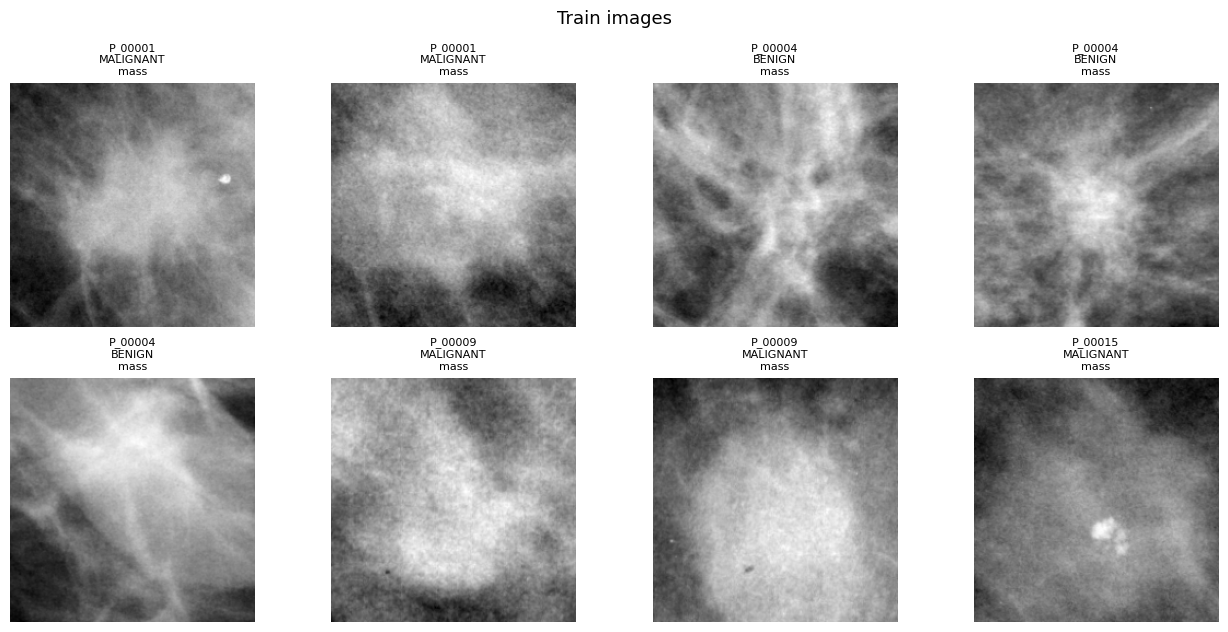

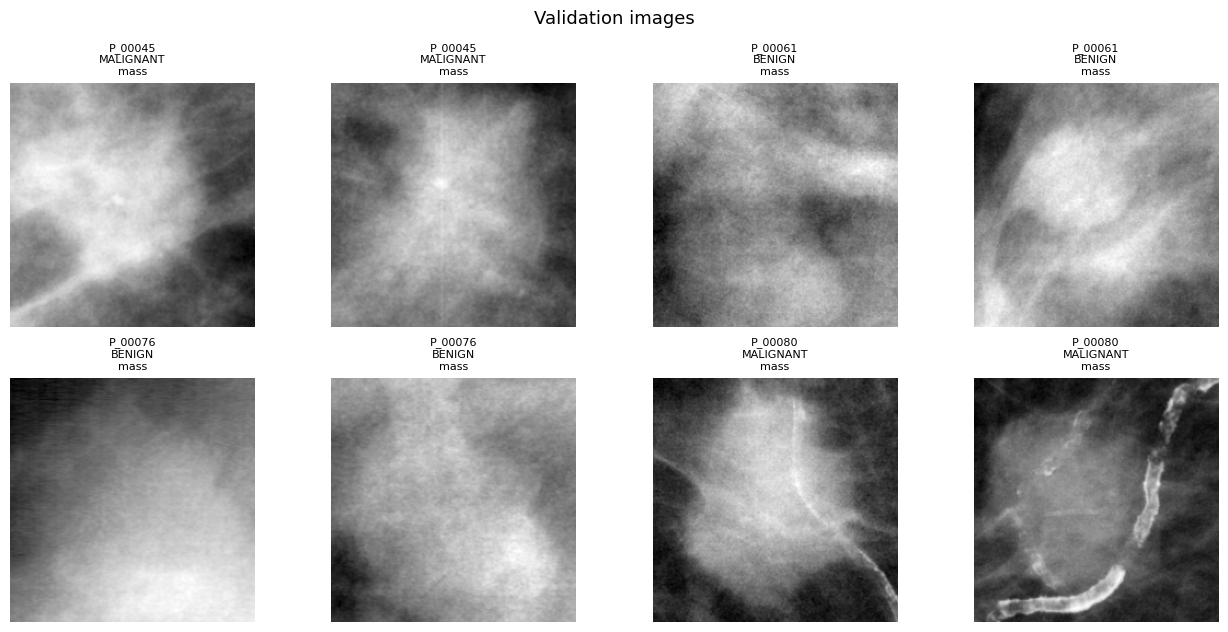

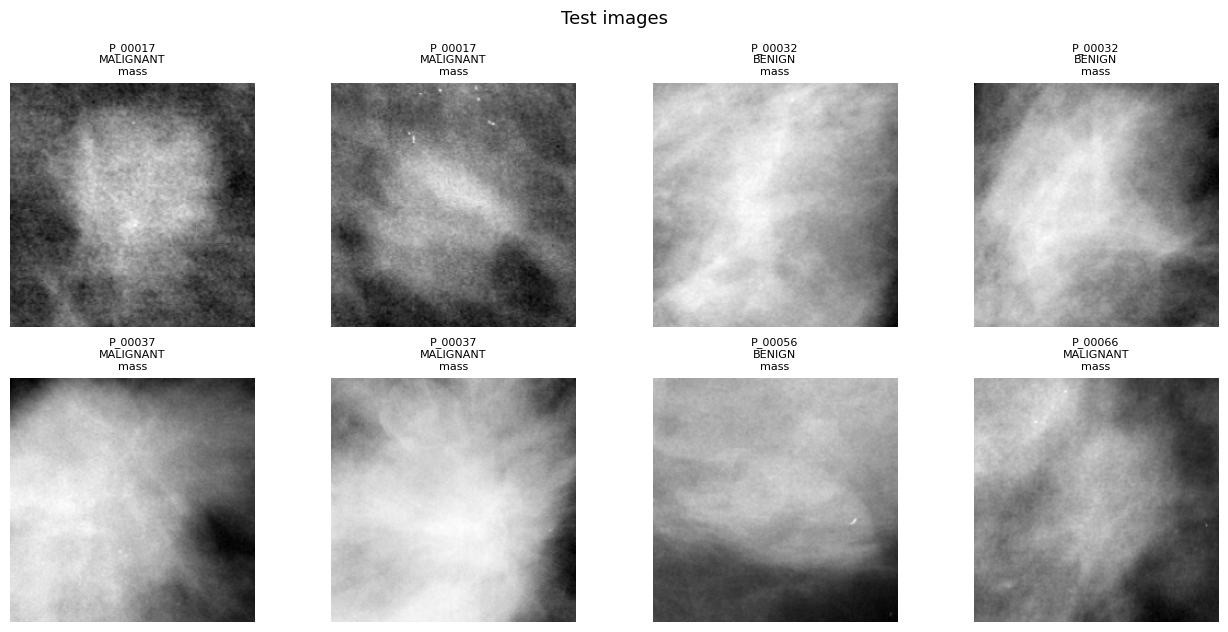

Train before augment: 2462 images | malignant=1019 benign=1443 (malignant rate 0.414)
BALANCE_CLASSES=True -> target 4329 images per class (+2886 benign copies, +3310 malignant copies)


Augmenting train:   0%|          | 0/6196 [00:00<?, ?img/s]

Train after augment: 8658 images | malignant=4329 benign=4329 (malignant rate 0.500) in 20.5s


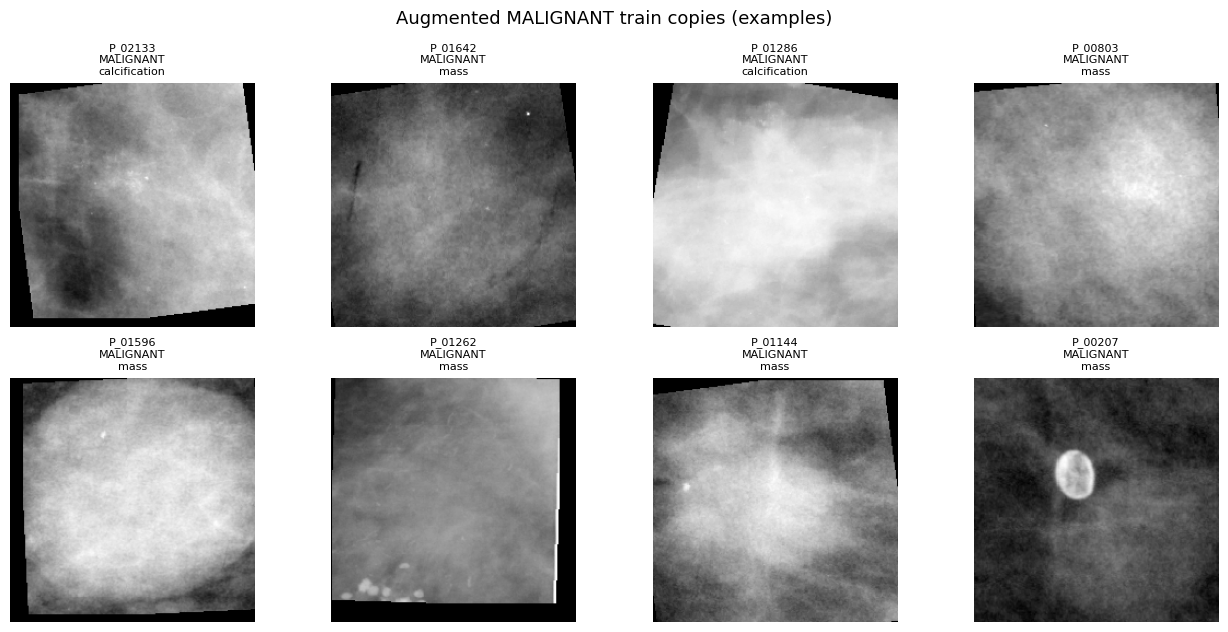

In [9]:
import os
import time
import concurrent.futures
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

NUM_WORKERS = min(8, (os.cpu_count() or 4) * 2)  # I/O-bound → oversubscribe cores a bit
THUMBNAIL_FOR_SCORE = 256  # small copy used only to pick photo vs mask, not for training


def find_jpeg_root():
    candidates = [DATA_ROOT / "jpeg", KAGGLE_INPUT / "jpeg", LOCAL_DATA / "jpeg"]
    if Path("/kaggle/input").is_dir():
        candidates.extend(p for p in Path("/kaggle/input").rglob("jpeg") if p.is_dir())
    for p in candidates:
        if p.is_dir():
            return p
    return None


JPEG_ROOT = find_jpeg_root()
print("JPEG root:", JPEG_ROOT)
print("Tensors will be placed on:", DEVICE)
print(f"Parallel image loading workers: {NUM_WORKERS}")

# One fixed patch per image. Multi-patch bags are NOT used here: each extra
# patch would multiply DeepProbLog ExactEngine queries.
def build_patch_transform(train=False):
    """ROI crop -> IMAGE_SIZE x IMAGE_SIZE tensor.

    CBIS 'cropped' JPEGs are already lesion-centered patches of the full mammo.
    PATCH_MODE controls how we cut a fixed square from that ROI without always
    stretching the whole box (which destroys fine margin detail).
    """
    if PATCH_MODE == "resize":
        return transforms.Compose([
            transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
            transforms.ToTensor(),
        ])
    # center / random: scale so short side is at least IMAGE_SIZE, then crop
    if train and PATCH_MODE == "random":
        return transforms.Compose([
            transforms.RandomResizedCrop(
                IMAGE_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1),
                interpolation=transforms.InterpolationMode.BILINEAR,
            ),
            transforms.ToTensor(),
        ])
    return transforms.Compose([
        transforms.Resize(IMAGE_SIZE, interpolation=transforms.InterpolationMode.BILINEAR),
        transforms.CenterCrop(IMAGE_SIZE),
        transforms.ToTensor(),
    ])

tfm_train = build_patch_transform(train=True)
tfm_eval = build_patch_transform(train=False)
print(f"PATCH_MODE={PATCH_MODE!r}  IMAGE_SIZE={IMAGE_SIZE}  "
      f"(train={'RandomResizedCrop' if PATCH_MODE=='random' else PATCH_MODE}, "
      f"val/test={'center crop' if PATCH_MODE!='resize' else 'resize'})")


def clean_relpath(value):
    if pd.isna(value):
        return None
    text = str(value).strip().strip('"').split("\n")[0].strip()
    return text or None


_JPEG_INDEX = None


def jpeg_folder_index():
    """Map folder names that actually contain images to their paths.

    The awsaf49 jpeg tree is not the CSV DICOM path. Images usually live in a
    folder named by the series UID (3rd path component), as 1-1.jpg / 1-2.jpg.
    """
    global _JPEG_INDEX
    if _JPEG_INDEX is not None:
        return _JPEG_INDEX
    index = {}
    if JPEG_ROOT is None or not JPEG_ROOT.is_dir():
        _JPEG_INDEX = index
        return index
    t0 = time.perf_counter()
    for dirpath, _dirnames, filenames in os.walk(JPEG_ROOT):
        imgs = [f for f in filenames if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        if not imgs:
            continue
        folder = Path(dirpath)
        index[folder.name] = folder
    _JPEG_INDEX = index
    dt = time.perf_counter() - t0
    print(f"Indexed {len(index)} jpeg folders in {dt:.1f}s")
    print("example jpeg folders:", list(index)[:5])
    return index


def image_photo_score(path):
    """Higher score = more like a mammogram crop, less like a binary ROI mask.

    Scored on a small thumbnail: we only need the ranking between candidate
    files in the same folder, not exact statistics, so this is much cheaper
    than scoring the full-resolution image.
    """
    with Image.open(path) as im:
        im = im.convert("L")
        im.thumbnail((THUMBNAIL_FOR_SCORE, THUMBNAIL_FOR_SCORE))
        arr = np.asarray(im, dtype=np.uint8)
    n_unique = int(len(np.unique(arr)))
    mid_gray = float(((arr > 15) & (arr < 240)).mean())
    return (n_unique, mid_gray, float(arr.std()))


def pick_image(folder, prefer_crop=True):
    folder = Path(folder)
    jpgs = sorted(folder.glob("*.jpg")) + sorted(folder.glob("*.jpeg")) + sorted(folder.glob("*.png"))
    if not jpgs:
        jpgs = sorted(folder.rglob("*.jpg")) + sorted(folder.rglob("*.jpeg")) + sorted(folder.rglob("*.png"))
    if not jpgs:
        return None
    if len(jpgs) == 1:
        return jpgs[0]
    # CBIS crop/mask folders contain 1-1.jpg and 1-2.jpg, and the CSV columns
    # are often swapped. Prefer the file with many gray levels (photo), not a mask.
    return max(jpgs, key=image_photo_score)


def resolve_jpeg(row):
    if JPEG_ROOT is None:
        return None
    index = jpeg_folder_index()
    for col in ("cropped image file path", "image file path"):
        rel = clean_relpath(row.get(col))
        if not rel:
            continue
        parts = [p for p in rel.replace("\\", "/").split("/") if p]
        if not parts:
            continue
        prefer_crop = col.startswith("cropped")
        exact = JPEG_ROOT / rel.replace(".dcm", ".jpg")
        if exact.is_file():
            return exact
        keys = []
        # Do not use Path.stem here. DICOM UIDs contain dots, so stem()
        # would chop the series id and never match the jpeg folder name.
        for part in parts:
            key = part[:-4] if part.lower().endswith(".dcm") else part
            if key:
                keys.append(key)
        seen = set()
        for key in keys:
            if not key or key in seen:
                continue
            seen.add(key)
            folder = index.get(key)
            if folder is None and (JPEG_ROOT / key).is_dir():
                folder = JPEG_ROOT / key
            if folder is None:
                continue
            img = pick_image(folder, prefer_crop=prefer_crop)
            if img is not None:
                return img
    return None


def _to_device(t):
    """Move tensor to DEVICE; if CUDA fails mid-run, switch globally to CPU."""
    global DEVICE
    try:
        return t.to(DEVICE)
    except Exception as exc:
        print("Device move failed (", type(exc).__name__, ") → forcing CPU for the rest of the run.")
        DEVICE = torch.device("cpu")
        return t.to(DEVICE)


def concept_placeholder(row):
    """Used only when a JPEG is missing. These placeholders are for a smoke test, not a real-image run."""
    shape_c = row.get("shape_concept", "unknown")
    margin_c = row.get("margin_concept", "unknown")
    calc_c = row.get("calc_concept", "absent")
    t = torch.zeros(1, IMAGE_SIZE, IMAGE_SIZE)
    third = IMAGE_SIZE // 3
    t[0, :third, :] = {"irregular": 1.0, "regular": 0.55, "unknown": 0.15}.get(shape_c, 0.15)
    t[0, third:2 * third, :] = {"spiculated": 1.0, "circumscribed": 0.55, "other": 0.35, "unknown": 0.15}.get(margin_c, 0.15)
    t[0, 2 * third:, :] = {"suspicious": 1.0, "typically_benign": 0.55, "absent": 0.15}.get(calc_c, 0.15)
    return t


def load_tensor(row, train=False):
    path = resolve_jpeg(row)
    if path is not None and path.is_file():
        with Image.open(path) as img:
            tfm = tfm_train if train else tfm_eval
            tensor = _to_device(tfm(img.convert("L")))
            return tensor, str(path), False
    if not USE_SYNTHETIC_IF_MISSING:
        rel = clean_relpath(row.get("cropped image file path")) or clean_relpath(row.get("image file path"))
        raise FileNotFoundError(
            f"No JPEG for patient {row.get('patient_id')}. csv_path={rel!r}. "
            f"JPEG_ROOT={JPEG_ROOT}. Check the 'Indexed N jpeg folders' line above."
        )
    return _to_device(concept_placeholder(row)), None, True


def materialize_split(df, n_limit=None, split_name="split", train=False):
    if n_limit is not None:
        df = df.head(n_limit).copy()
    rows = list(df.iterrows())
    n = len(rows)
    tensors = [None] * n
    paths = [None] * n
    synths = [False] * n
    t_start = time.perf_counter()

    def _worker(item):
        i, (_, row) = item
        tensor, path, synthetic = load_tensor(row, train=train)
        return i, tensor, path, synthetic

    n_synth = 0
    with concurrent.futures.ThreadPoolExecutor(max_workers=NUM_WORKERS) as ex:
        futures = ex.map(_worker, enumerate(rows))
        for i, tensor, path, synthetic in tqdm(futures, total=n, desc=f"Materializing {split_name}", unit="img"):
            tensors[i] = tensor
            paths[i] = path
            synths[i] = synthetic
            n_synth += int(synthetic)

    elapsed = time.perf_counter() - t_start
    avg_ms = (elapsed / max(n, 1)) * 1000
    print(f"  loaded {n} tensors ({n_synth} synthetic) on {DEVICE} "
          f"in {elapsed:.1f}s (avg {avg_ms:.0f} ms/image, {NUM_WORKERS} workers)")

    records = []
    for (_, row), path, synthetic in zip(rows, paths, synths):
        rec = row.to_dict()
        rec["resolved_path"] = path
        rec["synthetic"] = synthetic
        records.append(rec)
    return tensors, pd.DataFrame(records)


# Build the folder index once, up front, before the thread pool starts —
# avoids every worker thread racing to build it redundantly on first access.
jpeg_folder_index()

limit = SMOKE_N_SAMPLES if SMOKE_TEST else None
t_all_start = time.perf_counter()
print("Materializing train"); train_tensors, df_train = materialize_split(df_train, limit, split_name="train", train=True)
print("Materializing val");   val_tensors, df_val = materialize_split(df_val, limit, split_name="val", train=False)
print("Materializing test");  test_tensors, df_test = materialize_split(df_test, limit, split_name="test", train=False)
print(f"Total materialization time: {time.perf_counter() - t_all_start:.1f}s")

if df_train["synthetic"].all():
    print("WARNING: all train images are synthetic placeholders — check JPEG_ROOT on Kaggle.")
    print("This is a smoke test only until real JPEGs load (synthetic count must be 0).")
elif df_train["synthetic"].any():
    print("WARNING: some train images are synthetic placeholders.")


def tensor_to_numpy(t):
    x = t.detach().cpu() if hasattr(t, "detach") else t
    if hasattr(x, "numpy"):
        x = x.numpy()
    x = np.squeeze(x)
    return x


def show_image_grid(title, df, tensors, n=None):
    n = min(int(n if n is not None else SHOW_N_IMAGES), len(df), len(tensors))
    if n == 0:
        print(title, ": no images")
        return
    cols = 4
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(13, 3.2 * rows))
    axes = np.atleast_1d(axes).ravel()
    for i in range(n):
        ax = axes[i]
        ax.imshow(tensor_to_numpy(tensors[i]), cmap="gray")
        row = df.iloc[i]
        synth = " [placeholder]" if bool(row.get("synthetic", False)) else ""
        ax.set_title(
            f"{row['patient_id']}{synth}\n{row['pathology']}\n{row['abnormality_kind']}",
            fontsize=8,
        )
        ax.axis("off")
    for j in range(n, len(axes)):
        axes[j].axis("off")
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    plt.show()


print("\nShowing loaded images (real JPEG if synthetic=0):")
show_image_grid("Train images", df_train, train_tensors)
show_image_grid("Validation images", df_val, val_tensors)
show_image_grid("Test images", df_test, test_tensors)


# ---- train-only augmentation (val/test stay unchanged) ----
aug_tfm = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=12, fill=0),
    transforms.RandomAffine(degrees=0, translate=(0.04, 0.04), scale=(0.92, 1.08), fill=0),
])


def augment_one(tensor, rng_seed):
    x = tensor.detach().cpu() if hasattr(tensor, "detach") else torch.as_tensor(tensor)
    x = x.to(dtype=torch.float32)
    if x.dim() == 2:
        x = x.unsqueeze(0)
    g = torch.Generator()
    g.manual_seed(int(rng_seed) % (2**31 - 1))
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(int(rng_seed) % (2**31 - 1))
        x = aug_tfm(x)
    return x


df_train_orig = df_train.reset_index(drop=True)
train_tensors_orig = list(train_tensors)
n_mal = int((df_train_orig["malignant"] == 1).sum())
n_ben = int((df_train_orig["malignant"] == 0).sum())
print(f"Train before augment: {len(df_train_orig)} images | malignant={n_mal} benign={n_ben} "
      f"(malignant rate {n_mal / max(len(df_train_orig), 1):.3f})")


def augmented_copies(indices, n_copies_total, seed_base, pbar=None):
    """Produce n_copies_total augmented copies by cycling through `indices`.

    Used for class balancing: the minority class needs more copies than the
    majority class, so we keep cycling (with a fresh shuffle each pass) until
    the requested count is reached. Every copy gets its own RNG seed.
    """
    rows, tensors = [], []
    if n_copies_total <= 0 or len(indices) == 0:
        return rows, tensors
    rng = random.Random(seed_base)
    order = list(indices)
    k = 0
    while len(tensors) < n_copies_total:
        rng.shuffle(order)
        for i in order:
            if len(tensors) >= n_copies_total:
                break
            rows.append(df_train_orig.iloc[i].to_dict())
            tensors.append(augment_one(train_tensors_orig[i], seed_base + 7919 * k + i))
            k += 1
            if pbar is not None:
                pbar.update(1)
    return rows, tensors


if N_AUGMENT > 0 or BALANCE_CLASSES:
    ben_idx = df_train_orig.index[df_train_orig["malignant"] == 0].tolist()
    mal_idx = df_train_orig.index[df_train_orig["malignant"] == 1].tolist()
    n_ben_extra = N_AUGMENT * n_ben
    n_mal_extra = N_AUGMENT * n_mal
    if BALANCE_CLASSES:
        # Both classes end up at the size of the larger augmented class.
        target_per_class = max(n_ben + n_ben_extra, n_mal + n_mal_extra)
        n_ben_extra = target_per_class - n_ben
        n_mal_extra = target_per_class - n_mal
        print(f"BALANCE_CLASSES=True -> target {target_per_class} images per class "
              f"(+{n_ben_extra} benign copies, +{n_mal_extra} malignant copies)")

    t_aug_start = time.perf_counter()
    pbar = tqdm(total=n_ben_extra + n_mal_extra, desc="Augmenting train", unit="img")
    ben_rows, ben_tensors = augmented_copies(ben_idx, n_ben_extra, RANDOM_SEED + 1000, pbar)
    mal_rows, mal_tensors = augmented_copies(mal_idx, n_mal_extra, RANDOM_SEED + 2000, pbar)
    pbar.close()
    aug_elapsed = time.perf_counter() - t_aug_start

    extra_rows = ben_rows + mal_rows
    extra_tensors = ben_tensors + mal_tensors
    df_train = pd.concat([df_train_orig, pd.DataFrame(extra_rows)], ignore_index=True)
    train_tensors = [_to_device(t) if torch.is_tensor(t) else t for t in (train_tensors_orig + extra_tensors)]

    n_mal_after = int((df_train["malignant"] == 1).sum())
    n_ben_after = int((df_train["malignant"] == 0).sum())
    print(f"Train after augment: {len(df_train)} images | malignant={n_mal_after} benign={n_ben_after} "
          f"(malignant rate {n_mal_after / max(len(df_train), 1):.3f}) in {aug_elapsed:.1f}s")
    if mal_tensors:
        show_image_grid("Augmented MALIGNANT train copies (examples)", pd.DataFrame(mal_rows), mal_tensors,
                        n=min(SHOW_N_IMAGES, len(mal_tensors)))
else:
    print("N_AUGMENT=0 and BALANCE_CLASSES=False — training on original train images only.")


## 9) Neural nets, spatial diagram, and DeepProbLog datasets

**What:** define the concept perception model (`BACKBONE=resnet18` by default), draw how four concept heads feed DeepProbLog, then wrap each row as a `malignant` query plus concept queries.

**Why:** DeepProbLog needs a neural predicate for each concept in the Prolog program. Concept queries teach the nets the CSV labels. The `malignant` query teaches the combination that the rules use. Networks are created later, once per training run, so each run starts from a fresh initialization.

**Backbone:** ImageNet-pretrained ResNet18 is shared across the four heads (grayscale repeated to 3 channels + ImageNet normalize). A tiny from-scratch CNN remains available via `BACKBONE="tiny"` for smoke tests. The shared trunk is registered under only one DeepProbLog `Network` optimizer so Adam does not step the same weights four times per batch.


BACKBONE='resnet18'  IMAGE_SIZE=224  FREEZE_BACKBONE_EPOCHS=2
ResNet18 spatial path:
  input 1ch->3ch                224 x 224  ch=3
  ResNet stem /2                112 x 112  ch=64
  layer1                        112 x 112  ch=64
  layer2 /2                     56 x 56  ch=128
  layer3 /2                     28 x 28  ch=256
  layer4 /2                     14 x 14  ch=512
  GAP -> 512-d                  1 x 1  ch=512


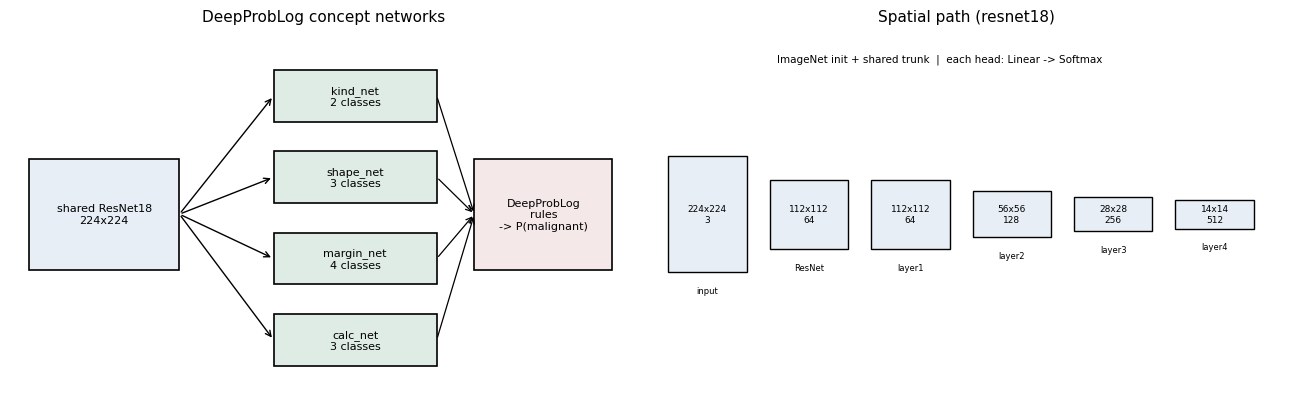

Networks factory ready. Fresh copies are created for the training run.
Dataset classes ready. Query datasets are built inside the training function so grid search can rebuild them.


In [10]:
import time
# ImageNet normalization (applied after repeating grayscale -> 3 channels)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def _prepare_input(x, device, three_channel=False):
    """DeepProbLog may pass CPU / unbatched tensors — normalize shape and device."""
    if not torch.is_tensor(x):
        x = torch.as_tensor(x)
    x = x.to(device, dtype=torch.float32)
    if x.dim() == 3:  # [C,H,W] -> [1,C,H,W]
        x = x.unsqueeze(0)
    if three_channel:
        if x.size(1) == 1:
            x = x.repeat(1, 3, 1, 1)
        mean = x.new_tensor(IMAGENET_MEAN).view(1, 3, 1, 1)
        std = x.new_tensor(IMAGENET_STD).view(1, 3, 1, 1)
        x = (x - mean) / std
    return x


class ConceptCNN(nn.Module):
    """Tiny from-scratch CNN (BACKBONE='tiny'). Kept for smoke tests / ablation."""

    def __init__(self, n_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(True),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(True),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(True),
            nn.AdaptiveAvgPool2d(4),
        )
        self.classifier = nn.Linear(64 * 4 * 4, n_classes)
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x, return_prob=True):
        x = _prepare_input(x, next(self.parameters()).device, three_channel=False)
        logits = self.classifier(self.net(x).flatten(1))
        return self.softmax(logits) if return_prob else logits


class ResNetBackbone(nn.Module):
    """ImageNet ResNet18 trunk -> 512-d pooled features."""

    def __init__(self, pretrained=True):
        super().__init__()
        weights = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.resnet18(weights=weights)
        net.fc = nn.Identity()
        self.net = net
        self.out_dim = 512

    def forward(self, x):
        return self.net(x)


class ConceptHead(nn.Module):
    """One DeepProbLog neural predicate: shared ResNet trunk + linear head + softmax.

    Only the head that gets register_backbone=True owns the trunk as a submodule
    (and therefore in parameters() / its Adam). Other heads hold a plain reference
    so DeepProbLog's optimizer.step() — which steps every Network each batch —
    does not Adam-update the shared weights four times.
    """

    def __init__(self, backbone: ResNetBackbone, n_classes: int, register_backbone: bool = False):
        super().__init__()
        self.register_backbone = register_backbone
        if register_backbone:
            self.backbone = backbone
        else:
            object.__setattr__(self, "_backbone_ref", backbone)
        self.head = nn.Linear(backbone.out_dim, n_classes)
        self.softmax = nn.Softmax(dim=1)

    def _backbone(self):
        return self.backbone if self.register_backbone else self._backbone_ref

    def forward(self, x, return_prob=True):
        bb = self._backbone()
        x = _prepare_input(x, next(bb.parameters()).device, three_channel=True)
        feats = bb(x)
        logits = self.head(feats)
        return self.softmax(logits) if return_prob else logits


def build_concept_nets(device=DEVICE):
    """Return (kind, shape, margin, calc, backbone_or_None) on device."""
    if BACKBONE == "tiny":
        kind = ConceptCNN(2).to(device)
        shape = ConceptCNN(3).to(device)
        margin = ConceptCNN(4).to(device)
        calc = ConceptCNN(3).to(device)
        return kind, shape, margin, calc, None

    if BACKBONE != "resnet18":
        raise ValueError(f"Unknown BACKBONE={BACKBONE!r}; use 'resnet18' or 'tiny'")

    backbone = ResNetBackbone(pretrained=True).to(device)
    kind = ConceptHead(backbone, 2, register_backbone=True).to(device)
    shape = ConceptHead(backbone, 3, register_backbone=False).to(device)
    margin = ConceptHead(backbone, 4, register_backbone=False).to(device)
    calc = ConceptHead(backbone, 3, register_backbone=False).to(device)
    return kind, shape, margin, calc, backbone


def set_backbone_trainable(backbone, trainable: bool):
    if backbone is None:
        return
    for p in backbone.parameters():
        p.requires_grad = bool(trainable)
    print(f"Backbone requires_grad={trainable}")


def make_network_optimizers(kind_net, shape_net, margin_net, calc_net, backbone, lr):
    """Adam per DeepProbLog Network. Shared trunk only in kind_net's optimizer."""
    if backbone is None:
        return (
            torch.optim.Adam(kind_net.parameters(), lr=lr),
            torch.optim.Adam(shape_net.parameters(), lr=lr),
            torch.optim.Adam(margin_net.parameters(), lr=lr),
            torch.optim.Adam(calc_net.parameters(), lr=lr),
        )
    backbone_lr = lr * BACKBONE_LR_MULT
    bb_params = [p for p in backbone.parameters() if p.requires_grad]
    kind_groups = [{"params": kind_net.head.parameters(), "lr": lr}]
    if bb_params:
        kind_groups.insert(0, {"params": bb_params, "lr": backbone_lr})
    kind_opt = torch.optim.Adam(kind_groups)
    shape_opt = torch.optim.Adam(shape_net.head.parameters(), lr=lr)
    margin_opt = torch.optim.Adam(margin_net.head.parameters(), lr=lr)
    calc_opt = torch.optim.Adam(calc_net.head.parameters(), lr=lr)
    return kind_opt, shape_opt, margin_opt, calc_opt



# Ordered label lists must match PROGRAM_FALLBACK / DeepProbLog class order.
KIND_LABELS = ["mass", "calcification"]
SHAPE_LABELS = ["regular", "irregular", "unknown"]
MARGIN_LABELS = ["circumscribed", "spiculated", "other", "unknown"]
CALC_LABELS = ["absent", "typically_benign", "suspicious"]


def label_to_index(series, labels):
    idx = {lab: i for i, lab in enumerate(labels)}
    out = []
    for v in series:
        key = str(v).strip()
        if key not in idx:
            key = "unknown" if "unknown" in idx else labels[0]
        out.append(idx[key])
    return torch.tensor(out, dtype=torch.long)


def inverse_freq_weights(y_indices, n_classes):
    """Inverse-frequency class weights (normalized to mean 1)."""
    counts = torch.bincount(y_indices.cpu(), minlength=n_classes).float().clamp(min=1.0)
    w = counts.sum() / (n_classes * counts)
    return (w / w.mean()).to(DEVICE)


def concept_agree_from_logits(logits, y):
    return float((logits.argmax(dim=1) == y).float().mean().item())


def _head_param_list(kind_net, shape_net, margin_net, calc_net, backbone):
    if backbone is None:
        return (
            list(kind_net.parameters()) + list(shape_net.parameters())
            + list(margin_net.parameters()) + list(calc_net.parameters())
        )
    return (
        list(kind_net.head.parameters()) + list(shape_net.head.parameters())
        + list(margin_net.head.parameters()) + list(calc_net.head.parameters())
    )


def run_concept_warmup(kind_net, shape_net, margin_net, calc_net, backbone,
                       train_tensors, df_train, val_tensors=None, df_val=None, seed=None):
    """Supervised CE warm-up on CSV concepts before DeepProbLog.

    Inverse-frequency class weights (esp. margin/shape). Freezes ResNet trunk for
    CONCEPT_WARMUP_FREEZE_EPOCHS, then fine-tunes at BACKBONE_LR_MULT * LR.
    """
    if CONCEPT_WARMUP_EPOCHS <= 0:
        print("CONCEPT_WARMUP_EPOCHS=0 — skipping supervised concept warm-up.")
        return None

    print(f"\n=== Concept CE warm-up: {CONCEPT_WARMUP_EPOCHS} epochs, "
          f"batch={CONCEPT_WARMUP_BATCH}, freeze_first={CONCEPT_WARMUP_FREEZE_EPOCHS} ===")

    df_w = globals().get("df_train_orig", df_train)

    y_kind = label_to_index(df_train["kind_concept"], KIND_LABELS)
    y_shape = label_to_index(df_train["shape_concept"], SHAPE_LABELS)
    y_margin = label_to_index(df_train["margin_concept"], MARGIN_LABELS)
    y_calc = label_to_index(df_train["calc_concept"], CALC_LABELS)

    w_kind = inverse_freq_weights(label_to_index(df_w["kind_concept"], KIND_LABELS), len(KIND_LABELS))
    w_shape = inverse_freq_weights(label_to_index(df_w["shape_concept"], SHAPE_LABELS), len(SHAPE_LABELS))
    w_margin = inverse_freq_weights(label_to_index(df_w["margin_concept"], MARGIN_LABELS), len(MARGIN_LABELS))
    w_calc = inverse_freq_weights(label_to_index(df_w["calc_concept"], CALC_LABELS), len(CALC_LABELS))
    print("Class weights kind :", [round(float(x), 3) for x in w_kind])
    print("Class weights shape:", [round(float(x), 3) for x in w_shape])
    print("Class weights margin:", [round(float(x), 3) for x in w_margin])
    print("Class weights calc :", [round(float(x), 3) for x in w_calc])

    crit_kind = nn.CrossEntropyLoss(weight=w_kind)
    crit_shape = nn.CrossEntropyLoss(weight=w_shape)
    crit_margin = nn.CrossEntropyLoss(weight=w_margin)
    crit_calc = nn.CrossEntropyLoss(weight=w_calc)

    x_cpu = torch.stack([t.detach().cpu() if torch.is_tensor(t) else t for t in train_tensors])
    from torch.utils.data import TensorDataset, DataLoader as TorchLoader
    ds = TensorDataset(x_cpu, y_kind, y_shape, y_margin, y_calc)
    loader = TorchLoader(
        ds, batch_size=CONCEPT_WARMUP_BATCH, shuffle=True,
        generator=torch.Generator().manual_seed(RANDOM_SEED if seed is None else seed),
    )

    def build_opt(freeze_backbone):
        set_backbone_trainable(backbone, (not freeze_backbone) if backbone is not None else True)
        head_params = _head_param_list(kind_net, shape_net, margin_net, calc_net, backbone)
        if backbone is None or freeze_backbone:
            return torch.optim.Adam(head_params, lr=LR)
        return torch.optim.Adam([
            {"params": [p for p in backbone.parameters() if p.requires_grad], "lr": LR * BACKBONE_LR_MULT},
            {"params": head_params, "lr": LR},
        ])

    freeze = backbone is not None and CONCEPT_WARMUP_FREEZE_EPOCHS > 0
    opt = build_opt(freeze_backbone=freeze)

    history = []
    t0 = time.perf_counter()
    for ep in range(CONCEPT_WARMUP_EPOCHS):
        if backbone is not None and ep == CONCEPT_WARMUP_FREEZE_EPOCHS and CONCEPT_WARMUP_FREEZE_EPOCHS > 0:
            print(f"  warm-up: unfreezing backbone at epoch {ep + 1}")
            freeze = False
            opt = build_opt(freeze_backbone=False)

        kind_net.train(); shape_net.train(); margin_net.train(); calc_net.train()
        if backbone is not None:
            backbone.train()
        total, n = 0.0, 0
        for xb, yk, ys, ym, yc in loader:
            xb = xb.to(DEVICE)
            yk, ys, ym, yc = yk.to(DEVICE), ys.to(DEVICE), ym.to(DEVICE), yc.to(DEVICE)
            opt.zero_grad()
            loss = (
                crit_kind(kind_net(xb, return_prob=False), yk)
                + crit_shape(shape_net(xb, return_prob=False), ys)
                + crit_margin(margin_net(xb, return_prob=False), ym)
                + crit_calc(calc_net(xb, return_prob=False), yc)
            )
            loss.backward()
            opt.step()
            total += float(loss.item()) * len(yk)
            n += len(yk)
        row = {"epoch": ep + 1, "loss": total / max(n, 1), "frozen": freeze}
        print(f"  warm-up epoch {ep + 1}/{CONCEPT_WARMUP_EPOCHS}  loss={row['loss']:.4f}  frozen={freeze}")
        history.append(row)

    val_agree = {}
    if val_tensors is not None and df_val is not None and len(df_val) > 0:
        kind_net.eval(); shape_net.eval(); margin_net.eval(); calc_net.eval()
        if backbone is not None:
            backbone.eval()
        with torch.no_grad():
            vk = label_to_index(df_val["kind_concept"], KIND_LABELS).to(DEVICE)
            vs = label_to_index(df_val["shape_concept"], SHAPE_LABELS).to(DEVICE)
            vm = label_to_index(df_val["margin_concept"], MARGIN_LABELS).to(DEVICE)
            vc = label_to_index(df_val["calc_concept"], CALC_LABELS).to(DEVICE)
            ag_k = ag_s = ag_m = ag_c = 0.0
            bs = CONCEPT_WARMUP_BATCH
            for i0 in range(0, len(df_val), bs):
                batch = [val_tensors[i].detach().cpu() for i in range(i0, min(i0 + bs, len(df_val)))]
                xb = torch.stack(batch).to(DEVICE)
                sl = slice(i0, i0 + len(batch))
                ag_k += concept_agree_from_logits(kind_net(xb, return_prob=False), vk[sl]) * len(batch)
                ag_s += concept_agree_from_logits(shape_net(xb, return_prob=False), vs[sl]) * len(batch)
                ag_m += concept_agree_from_logits(margin_net(xb, return_prob=False), vm[sl]) * len(batch)
                ag_c += concept_agree_from_logits(calc_net(xb, return_prob=False), vc[sl]) * len(batch)
            nval = float(len(df_val))
            val_agree = {
                "kind": ag_k / nval, "shape": ag_s / nval,
                "margin": ag_m / nval, "calc": ag_c / nval,
            }
            print("  warm-up val agree@argmax: "
                  + ", ".join(f"{k}={v:.3f}" for k, v in val_agree.items()))

    ckpt_path = OUTPUT_DIR / "checkpoints" / f"concept_warmup_{BACKBONE}.pt"
    ckpt_path.parent.mkdir(parents=True, exist_ok=True)
    payload = {
        "backbone_name": BACKBONE,
        "kind_net": kind_net.state_dict(),
        "shape_net": shape_net.state_dict(),
        "margin_net": margin_net.state_dict(),
        "calc_net": calc_net.state_dict(),
        "history": history,
        "val_agree": val_agree,
    }
    if backbone is not None:
        payload["backbone"] = backbone.state_dict()
    torch.save(payload, ckpt_path)
    print(f"  warm-up done in {(time.perf_counter() - t0) / 60:.1f} min -> {ckpt_path}")
    return {"history": history, "val_agree": val_agree, "path": str(ckpt_path)}


def draw_concept_architecture(image_size=IMAGE_SIZE):
    """Draw shared-backbone (or tiny) concept nets feeding DeepProbLog."""
    print(f"BACKBONE={BACKBONE!r}  IMAGE_SIZE={image_size}  "
          f"FREEZE_BACKBONE_EPOCHS={FREEZE_BACKBONE_EPOCHS}")
    if BACKBONE == "resnet18":
        stages = [
            ("input 1ch->3ch", image_size, image_size, 3),
            ("ResNet stem /2", image_size // 2, image_size // 2, 64),
            ("layer1", image_size // 2, image_size // 2, 64),
            ("layer2 /2", image_size // 4, image_size // 4, 128),
            ("layer3 /2", image_size // 8, image_size // 8, 256),
            ("layer4 /2", image_size // 16, image_size // 16, 512),
            ("GAP -> 512-d", 1, 1, 512),
        ]
        print("ResNet18 spatial path:")
    else:
        h = w = int(image_size)
        stages = [("input (1 ch)", h, w, 1)]
        for name, ch in (("conv1 stride2", 16), ("conv2 stride2", 32), ("conv3 stride2", 64)):
            h = (h + 1) // 2
            w = (w + 1) // 2
            stages.append((f"{name} ({ch} ch)", h, w, ch))
        stages.append(("AdaptiveAvgPool2d(4)", 4, 4, 64))
        print("Tiny ConceptCNN spatial path:")
    for name, h, w, ch in stages:
        print(f"  {name:28s}  {h} x {w}  ch={ch}")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    ax = axes[0]
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis("off")
    ax.set_title("DeepProbLog concept networks", fontsize=11)
    trunk_label = (
        f"shared ResNet18\n{image_size}x{image_size}"
        if BACKBONE == "resnet18"
        else f"tiny CNN\n{image_size}x{image_size}"
    )
    ax.add_patch(plt.Rectangle((0.3, 3.5), 2.4, 3.0, fill=True, facecolor="#e8eef5", edgecolor="black", lw=1.2))
    ax.text(1.5, 5.0, trunk_label, ha="center", va="center", fontsize=8)
    heads = [
        (4.2, 8.2, "kind_net\n2 classes"),
        (4.2, 6.0, "shape_net\n3 classes"),
        (4.2, 3.8, "margin_net\n4 classes"),
        (4.2, 1.6, "calc_net\n3 classes"),
    ]
    for x, y, label in heads:
        ax.add_patch(plt.Rectangle((x, y - 0.7), 2.6, 1.4, fill=True, facecolor="#dfece6", edgecolor="black", lw=1.2))
        ax.text(x + 1.3, y, label, ha="center", va="center", fontsize=8)
        ax.annotate("", xy=(x, y), xytext=(2.7, 5.0), arrowprops=dict(arrowstyle="->", color="black", lw=1.0))
    ax.add_patch(plt.Rectangle((7.4, 3.5), 2.2, 3.0, fill=True, facecolor="#f5e8e8", edgecolor="black", lw=1.2))
    ax.text(8.5, 5.0, "DeepProbLog\nrules\n-> P(malignant)", ha="center", va="center", fontsize=8)
    for _, y, _ in heads:
        ax.annotate("", xy=(7.4, 5.0), xytext=(6.8, y), arrowprops=dict(arrowstyle="->", color="black", lw=0.9))

    ax = axes[1]
    ax.set_xlim(0, 12)
    ax.set_ylim(0, 8)
    ax.axis("off")
    ax.set_title(f"Spatial path ({BACKBONE})", fontsize=11)
    draw_stages = stages[:6] if len(stages) > 6 else stages
    max_side = max(max(s[1], 1) for s in draw_stages)
    xs = np.linspace(0.3, 10.0, len(draw_stages))
    for (name, h, w, ch), x in zip(draw_stages, xs):
        side = 0.5 + 2.0 * (h / max_side)
        y0 = 4.0 - side / 2
        ax.add_patch(plt.Rectangle((x, y0), 1.5, side, fill=True, facecolor="#e8eef5", edgecolor="black", lw=1.0))
        ax.text(x + 0.75, y0 + side / 2, f"{h}x{w}\n{ch}", ha="center", va="center", fontsize=6.5)
        ax.text(x + 0.75, y0 - 0.3, name.split()[0], ha="center", va="top", fontsize=6)
    ax.text(5.5, 7.3, "ImageNet init + shared trunk  |  each head: Linear -> Softmax", ha="center", fontsize=7.5)
    fig.tight_layout()
    plt.show()


draw_concept_architecture(IMAGE_SIZE)
print("Networks factory ready. Fresh copies are created for the training run.")

from problog.logic import Term, Constant
from deepproblog.dataset import Dataset, DataLoader, QueryDataset
from deepproblog.query import Query


class TensorSource:
    def __init__(self, tensors, device=None):
        self.tensors = tensors
        self.device = device

    def __getitem__(self, item):
        t = self.tensors[int(item[0])]
        if self.device is not None:
            t = t.to(self.device)
        return t


class BreastQueryDataset(Dataset):
    def __init__(self, split_name, df):
        self.split_name = split_name
        self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def _tensor_term(self, i):
        return Term("tensor", Term(self.split_name, Constant(i)))

    def to_query(self, i):
        row = self.df.iloc[i]
        return Query(Term("malignant", self._tensor_term(i)), p=float(row["malignant"]))

    def concept_queries(self):
        qs = []
        for i, row in self.df.iterrows():
            img = self._tensor_term(i)
            qs.append(Query(Term("shape", img, Term(row["shape_concept"])), p=1.0))
            qs.append(Query(Term("margin", img, Term(row["margin_concept"])), p=1.0))
            qs.append(Query(Term("calc", img, Term(row["calc_concept"])), p=1.0))
            qs.append(Query(Term("lesion_kind", img, Term(row["kind_concept"])), p=1.0))
        return qs


print("Dataset classes ready. Query datasets are built inside the training function so grid search can rebuild them.")


## 10a) Loss equations and label sources

Printed again with the query counts when training starts.

Stage 1 does not call DeepProbLog. Its loss is the sum of four class-weighted cross-entropies, one per concept head. The targets are the recorded concept indices. There is no malignancy term.

Stage 2 calls DeepProbLog `train_model`. Each image contributes one `malignant` query, with target probability equal to the pathology label, and four concept queries, with target probability 1.0 on the recorded concept. The loss on a query is cross-entropy between that target and the ExactEngine probability. `backward()` is called on that probability, so the malignancy term passes through the logic program. Queries inside a batch have equal weight, and there is no extra coefficient.


## 10) Concept warm-up, then train DeepProbLog

**What:** (1) supervised CE warm-up of the shared ResNet + four concept heads on CSV labels with inverse-frequency class weights; (2) DeepProbLog ExactEngine fine-tune with the same rules as before.

**Why:** result_3 showed remaining FPs/FNs are still shape/margin perception errors. Direct concept CE is a stronger signal than learning concepts only through the malignant query. Class weights boost rare labels such as spiculated / irregular.

Mass evidence is used only when `lesion_kind` is mass. Suspicious calc is used only when `lesion_kind` is calcification.


In [11]:
# import time
# from itertools import product
# from tqdm.auto import tqdm

# from deepproblog.engines import ExactEngine
# from deepproblog.model import Model
# from deepproblog.network import Network
# from deepproblog.train import train_model

# # Always write the notebook program. Do not reuse a stale Kaggle .pl from a previous run.
# program_path = OUTPUT_DIR / "breast_diagnosis.pl"
# program_path.write_text(PROGRAM_FALLBACK + "\n")
# print("Using program:", program_path.resolve())
# print(program_path.read_text())


# def _quick_prob(result):
#     mapping = result.result if hasattr(result, "result") else {}
#     if not mapping:
#         return 0.0
#     vals = []
#     for v in mapping.values():
#         if hasattr(v, "detach"):
#             vals.append(float(v.detach().cpu().item() if v.numel() == 1 else v.detach().cpu().mean()))
#         else:
#             vals.append(float(v))
#     return float(sum(vals) / len(vals)) if vals else 0.0


# def validation_macro_f1(trained_model, df):
#     """Score one trained model on the original validation images."""
#     y_true, y_pred = [], []
#     for i in range(len(df)):
#         q = Query(Term("malignant", Term("tensor", Term("val", Constant(i)))))
#         solved = trained_model.solve([q])
#         p = _quick_prob(solved[0]) if solved else 0.0
#         y_true.append(int(df.iloc[i]["malignant"]))
#         y_pred.append(int(p >= 0.5))
#     y_true, y_pred = np.array(y_true), np.array(y_pred)
#     tp = int(((y_pred == 1) & (y_true == 1)).sum())
#     tn = int(((y_pred == 0) & (y_true == 0)).sum())
#     fp = int(((y_pred == 1) & (y_true == 0)).sum())
#     fn = int(((y_pred == 0) & (y_true == 1)).sum())
#     f1_mal = 0.0 if (tp + fp) == 0 or (tp + fn) == 0 else (2 * tp / (2 * tp + fp + fn))
#     f1_ben = 0.0 if (tn + fn) == 0 or (tn + fp) == 0 else (2 * tn / (2 * tn + fn + fp))
#     return 0.5 * (f1_mal + f1_ben), {"tp": tp, "tn": tn, "fp": fp, "fn": fn, "f1_malignant": f1_mal, "f1_benign": f1_ben}


# def train_deepproblog(lr, batch_size, epochs, log_label="train"):
#     """Fresh nets + DeepProbLog model. Returns (model, train_set)."""
#     shape_net = ConceptCNN(3).to(DEVICE)
#     margin_net = ConceptCNN(4).to(DEVICE)
#     calc_net = ConceptCNN(3).to(DEVICE)
#     kind_net = ConceptCNN(2).to(DEVICE)

#     train_set_local = BreastQueryDataset("train", df_train)
#     train_queries_local = QueryDataset(train_set_local.to_queries() + train_set_local.concept_queries())

#     shape_w = Network(shape_net, "shape_net", batching=True)
#     margin_w = Network(margin_net, "margin_net", batching=True)
#     calc_w = Network(calc_net, "calc_net", batching=True)
#     kind_w = Network(kind_net, "kind_net", batching=True)
#     shape_w.optimizer = torch.optim.Adam(shape_net.parameters(), lr=lr)
#     margin_w.optimizer = torch.optim.Adam(margin_net.parameters(), lr=lr)
#     calc_w.optimizer = torch.optim.Adam(calc_net.parameters(), lr=lr)
#     kind_w.optimizer = torch.optim.Adam(kind_net.parameters(), lr=lr)

#     trained = Model(str(program_path), [shape_w, margin_w, calc_w, kind_w])
#     trained.set_engine(ExactEngine(trained), cache=False)
#     trained.add_tensor_source("train", TensorSource(train_tensors, device=DEVICE))
#     trained.add_tensor_source("val", TensorSource(val_tensors, device=DEVICE))
#     trained.add_tensor_source("test", TensorSource(test_tensors, device=DEVICE))

#     loader = DataLoader(train_queries_local, batch_size, shuffle=True, seed=RANDOM_SEED)
#     n_batches = len(loader)
#     # Print progress ~50 times per epoch instead of once at the very end,
#     # so a long run shows visible movement instead of looking frozen.
#     log_iter = max(1, n_batches // 50)
#     print(f"[{log_label}] epochs={epochs} batch={batch_size} lr={lr} "
#           f"queries={len(train_queries_local)} batches/epoch={n_batches} "
#           f"(printing every {log_iter} batches)")
#     t0 = time.perf_counter()
#     train_model(trained, loader, epochs, log_iter=log_iter)
#     elapsed = time.perf_counter() - t0
#     print(f"[{log_label}] finished in {elapsed/60:.1f} min "
#           f"({elapsed / (epochs * n_batches):.2f} s/batch avg)")
#     return trained, train_set_local, shape_net, margin_net, calc_net, kind_net


# best_params = {"lr": LR, "batch_size": BATCH_SIZE}
# grid_rows = []

# if RUN_GRID_SEARCH:
#     combos = list(product(GRID_LEARNING_RATES, GRID_BATCH_SIZES))
#     print(f"Grid search on validation macro F1: {len(combos)} combos x {SEARCH_EPOCHS} epoch(s) each.")
#     print("(short runs; final training below still uses the full EPOCHS)")
#     t_grid_start = time.perf_counter()
#     for combo_i, (lr_i, bs_i) in enumerate(combos, start=1):
#         label = f"grid {combo_i}/{len(combos)} lr={lr_i} batch={bs_i}"
#         t_trial_start = time.perf_counter()
#         try:
#             trial_model, _, *_ = train_deepproblog(lr_i, bs_i, SEARCH_EPOCHS, log_label=label)
#             f1_macro, detail = validation_macro_f1(trial_model, df_val)
#             row = {"lr": lr_i, "batch_size": bs_i, "search_epochs": SEARCH_EPOCHS, "val_f1_macro": f1_macro, **detail, "ok": True}
#             print(f"  -> val_f1_macro={f1_macro:.4f}")
#         except Exception as exc:
#             row = {"lr": lr_i, "batch_size": bs_i, "search_epochs": SEARCH_EPOCHS, "val_f1_macro": -1.0, "ok": False, "error": f"{type(exc).__name__}: {str(exc)[:180]}"}
#             print("  -> failed:", row["error"])
#         grid_rows.append(row)
#         if DEVICE.type == "cuda":
#             torch.cuda.empty_cache()

#         trial_elapsed = time.perf_counter() - t_trial_start
#         total_elapsed = time.perf_counter() - t_grid_start
#         avg_per_combo = total_elapsed / combo_i
#         remaining = avg_per_combo * (len(combos) - combo_i)
#         print(f"  combo {combo_i}/{len(combos)} took {trial_elapsed/60:.1f} min | "
#               f"elapsed so far {total_elapsed/60:.1f} min | "
#               f"estimated remaining ~{remaining/60:.1f} min")
#     grid_df = pd.DataFrame(grid_rows)
#     display(grid_df.sort_values("val_f1_macro", ascending=False))
#     ok_rows = [r for r in grid_rows if r.get("ok")]
#     if ok_rows:
#         winner = max(ok_rows, key=lambda r: r["val_f1_macro"])
#         best_params = {"lr": winner["lr"], "batch_size": int(winner["batch_size"])}
#         print("Best grid pair:", best_params, "val_f1_macro=", winner["val_f1_macro"])
#     else:
#         print("Grid search had no successful run. Using config LR / BATCH_SIZE.")
#     (OUTPUT_DIR / "hyperparam_grid.json").write_text(json.dumps({"best": best_params, "rows": grid_rows}, indent=2, default=str))
#     print("Saved", OUTPUT_DIR / "hyperparam_grid.json")
#     print(f"Total grid search time: {(time.perf_counter() - t_grid_start)/60:.1f} min")
# else:
#     print("RUN_GRID_SEARCH=False — using config LR and BATCH_SIZE.")

# LR = float(best_params["lr"])
# BATCH_SIZE = int(best_params["batch_size"])
# print(f"Final training with lr={LR} batch={BATCH_SIZE} epochs={EPOCHS}")
# t_final_start = time.perf_counter()
# model, train_set, shape_net, margin_net, calc_net, kind_net = train_deepproblog(LR, BATCH_SIZE, EPOCHS, log_label="final")
# print(f"Final training total time: {(time.perf_counter() - t_final_start)/60:.1f} min")
# val_set = BreastQueryDataset("val", df_val)
# test_set = BreastQueryDataset("test", df_test)
# print("Training finished.")

In [12]:
import time
import json
from pathlib import Path

import torch
from deepproblog.engines import ExactEngine
from deepproblog.model import Model
from deepproblog.network import Network
from deepproblog.train import train_model

program_path = OUTPUT_DIR / "breast_diagnosis.pl"
program_path.write_text(PROGRAM_FALLBACK + "\n")
print("Using program:", program_path.resolve())
print(program_path.read_text())

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)
CHECKPOINT_PATH = CHECKPOINT_DIR / f"final_model_checkpoint_{BACKBONE}.pt"

# Grid from the tiny-CNN run; reuse lr/batch unless you flip RUN_GRID_SEARCH_NOW.
RUN_GRID_SEARCH_NOW = False
best_params = {"lr": 0.0003, "batch_size": 2}

grid_json_path = OUTPUT_DIR / "hyperparam_grid.json"
if grid_json_path.is_file():
    saved = json.loads(grid_json_path.read_text())
    best_params = saved.get("best", best_params)
    print("Loaded previous grid search result:", best_params)
else:
    print("Using hardcoded lr/batch from prior grid:", best_params)


def _quick_prob(result):
    mapping = result.result if hasattr(result, "result") else {}
    if not mapping:
        return 0.0
    vals = []
    for v in mapping.values():
        if hasattr(v, "detach"):
            vals.append(float(v.detach().cpu().item() if v.numel() == 1 else v.detach().cpu().mean()))
        else:
            vals.append(float(v))
    return float(sum(vals) / len(vals)) if vals else 0.0


def validation_macro_f1(trained_model, df):
    y_true, y_pred = [], []
    for i in range(len(df)):
        q = Query(Term("malignant", Term("tensor", Term("val", Constant(i)))))
        solved = trained_model.solve([q])
        p = _quick_prob(solved[0]) if solved else 0.0
        y_true.append(int(df.iloc[i]["malignant"]))
        y_pred.append(int(p >= 0.5))
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    tn = int(((y_pred == 0) & (y_true == 0)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    f1_mal = 0.0 if (tp + fp) == 0 or (tp + fn) == 0 else (2 * tp / (2 * tp + fp + fn))
    f1_ben = 0.0 if (tn + fn) == 0 or (tn + fp) == 0 else (2 * tn / (2 * tn + fn + fp))
    return 0.5 * (f1_mal + f1_ben), {"tp": tp, "tn": tn, "fp": fp, "fn": fn, "f1_malignant": f1_mal, "f1_benign": f1_ben}


def build_fresh_model(lr, freeze_backbone=False, nets=None):
    if nets is None:
        kind_net, shape_net, margin_net, calc_net, backbone = build_concept_nets(DEVICE)
    else:
        kind_net, shape_net, margin_net, calc_net, backbone = nets
    if freeze_backbone:
        set_backbone_trainable(backbone, False)
    else:
        set_backbone_trainable(backbone, True)

    kind_w = Network(kind_net, "kind_net", batching=True)
    shape_w = Network(shape_net, "shape_net", batching=True)
    margin_w = Network(margin_net, "margin_net", batching=True)
    calc_w = Network(calc_net, "calc_net", batching=True)

    kind_opt, shape_opt, margin_opt, calc_opt = make_network_optimizers(
        kind_net, shape_net, margin_net, calc_net, backbone, lr
    )
    kind_w.optimizer = kind_opt
    shape_w.optimizer = shape_opt
    margin_w.optimizer = margin_opt
    calc_w.optimizer = calc_opt

    trained = Model(str(program_path), [shape_w, margin_w, calc_w, kind_w])
    trained.set_engine(ExactEngine(trained), cache=False)
    trained.add_tensor_source("train", TensorSource(train_tensors, device=DEVICE))
    trained.add_tensor_source("val", TensorSource(val_tensors, device=DEVICE))
    trained.add_tensor_source("test", TensorSource(test_tensors, device=DEVICE))
    nets = (kind_net, shape_net, margin_net, calc_net, backbone)
    return trained, nets


def save_checkpoint(epoch, nets, lr, batch_size, backbone_frozen, path=CHECKPOINT_PATH):
    kind_net, shape_net, margin_net, calc_net, backbone = nets
    payload = {
        "epoch": epoch,
        "backbone_name": BACKBONE,
        "backbone_frozen": backbone_frozen,
        "kind_net": kind_net.state_dict(),
        "shape_net": shape_net.state_dict(),
        "margin_net": margin_net.state_dict(),
        "calc_net": calc_net.state_dict(),
        "lr": lr,
        "batch_size": batch_size,
    }
    if backbone is not None:
        payload["backbone"] = backbone.state_dict()
    torch.save(payload, path)
    print(f"  checkpoint saved (epoch {epoch}, frozen={backbone_frozen}) -> {path}")


def load_checkpoint_if_any(nets, path=CHECKPOINT_PATH):
    """Resume only if checkpoint matches current BACKBONE; else start fresh."""
    if not path.is_file():
        return 0
    kind_net, shape_net, margin_net, calc_net, backbone = nets
    ckpt = torch.load(path, map_location=DEVICE)
    if ckpt.get("backbone_name") != BACKBONE:
        print(f"Ignoring checkpoint at {path}: backbone {ckpt.get('backbone_name')!r} != {BACKBONE!r}")
        return 0
    try:
        kind_net.load_state_dict(ckpt["kind_net"])
        shape_net.load_state_dict(ckpt["shape_net"])
        margin_net.load_state_dict(ckpt["margin_net"])
        calc_net.load_state_dict(ckpt["calc_net"])
        if backbone is not None and "backbone" in ckpt:
            backbone.load_state_dict(ckpt["backbone"])
    except Exception as exc:
        print(f"Ignoring incompatible checkpoint ({type(exc).__name__}: {exc})")
        return 0
    print(f"Resuming after epoch {ckpt['epoch']} (lr={ckpt['lr']}, batch={ckpt['batch_size']})")
    return int(ckpt["epoch"])


def refresh_optimizers(trained, nets, lr, freeze_backbone):
    kind_net, shape_net, margin_net, calc_net, backbone = nets
    set_backbone_trainable(backbone, not freeze_backbone)
    kind_opt, shape_opt, margin_opt, calc_opt = make_network_optimizers(
        kind_net, shape_net, margin_net, calc_net, backbone, lr
    )
    trained.networks["kind_net"].optimizer = kind_opt
    trained.networks["shape_net"].optimizer = shape_opt
    trained.networks["margin_net"].optimizer = margin_opt
    trained.networks["calc_net"].optimizer = calc_opt


if RUN_GRID_SEARCH_NOW:
    raise RuntimeError("RUN_GRID_SEARCH_NOW=True — grid search not re-wired for ResNet in this cell.")

LR = float(best_params["lr"])
BATCH_SIZE = int(best_params["batch_size"])
print(f"Final training with backbone={BACKBONE!r} lr={LR} batch={BATCH_SIZE} epochs={EPOCHS} "
      f"concept_warmup={CONCEPT_WARMUP_EPOCHS}")

# 1) Build nets and run supervised concept CE warm-up (class-weighted).
kind_net, shape_net, margin_net, calc_net, shared_backbone = build_concept_nets(DEVICE)
warmup_metrics = run_concept_warmup(
    kind_net, shape_net, margin_net, calc_net, shared_backbone,
    train_tensors, df_train, val_tensors=val_tensors, df_val=df_val,
)
nets = (kind_net, shape_net, margin_net, calc_net, shared_backbone)

# 2) DeepProbLog fine-tune. After warm-up, keep trunk trainable at low LR.
freeze_now = False
if CONCEPT_WARMUP_EPOCHS <= 0:
    freeze_now = BACKBONE == "resnet18" and FREEZE_BACKBONE_EPOCHS > 0

trained, nets = build_fresh_model(LR, freeze_backbone=freeze_now, nets=nets)
start_epoch = load_checkpoint_if_any(nets, CHECKPOINT_PATH)

if start_epoch >= FREEZE_BACKBONE_EPOCHS and freeze_now:
    refresh_optimizers(trained, nets, LR, freeze_backbone=False)
    freeze_now = False

train_set = BreastQueryDataset("train", df_train)
train_queries = QueryDataset(train_set.to_queries() + train_set.concept_queries())
loader = DataLoader(train_queries, BATCH_SIZE, shuffle=True, seed=RANDOM_SEED)
n_batches = len(loader)
log_iter = max(1, n_batches // 50)
print(f"queries={len(train_queries)} batches/epoch={n_batches} (printing every {log_iter} batches)")

n_images = len(train_set)
n_queries = len(train_queries)
n_concept_queries = n_queries - n_images
print("\nSTAGE LOSS SPECIFICATION")
print("Stage 1 labels: concept labels only. The logic program is not in this loss, and there is no malignancy term.")
print("L_stage1 = CE(kind) + CE(shape) + CE(margin) + CE(calc)")
print("Each CE is inverse-frequency class-weighted cross-entropy. The target is the recorded concept index.")
print("Stage 2 labels: both. Malignancy target p = pathology, 0 or 1. Concept target p = 1.0 on the recorded concept.")
print(f"Stage 2 queries in this run: {n_images} malignant + {n_concept_queries} concept = {n_queries}.")
print("For a solved query with ExactEngine probability q and target p, batch size B:")
print("L(q) = -(p * log(q) + (1 - p) * log(1 - q)) / B")
print("The batch loss is the sum of L(q). DeepProbLog calls backward() on q.")
print("B is the number of solved queries in the batch. Every query has the same weight. No extra coefficient.")
print("Concept queries are four times as numerous as malignancy queries because each image adds four of them.")


def _score_malignant(trained_model, split_name, n):
    """Query probability only. This is not the max of the rule bodies."""
    probabilities = []
    for i in range(n):
        query = Query(Term("malignant", Term("tensor", Term(split_name, Constant(i)))))
        solved = trained_model.solve([query])
        probabilities.append(_quick_prob(solved[0]) if solved else 0.0)
        if (i + 1) % 50 == 0 or i + 1 == n:
            print(f"  {split_name} {i + 1}/{n}")
    return np.asarray(probabilities, dtype=float)


if start_epoch == 0:
    print("Scoring stage 1 before DeepProbLog fine-tuning. Decision score = query probability.")
    stage1_val_prob = _score_malignant(trained, "val", len(df_val))
    stage1_test_prob = _score_malignant(trained, "test", len(df_test))
    np.save(OUTPUT_DIR / "stage1_val_prob.npy", stage1_val_prob)
    np.save(OUTPUT_DIR / "stage1_test_prob.npy", stage1_test_prob)
    from sklearn.metrics import roc_auc_score
    print("stage1 val AUC", round(float(roc_auc_score(df_val["malignant"], stage1_val_prob)), 3))
    print("stage1 test AUC", round(float(roc_auc_score(df_test["malignant"], stage1_test_prob)), 3))
else:
    print("Resuming a checkpoint, so stage 1 is not scored again.")

t_final_start = time.perf_counter()
for epoch in range(start_epoch, EPOCHS):
    if BACKBONE == "resnet18" and epoch == FREEZE_BACKBONE_EPOCHS and FREEZE_BACKBONE_EPOCHS > 0:
        print(f"\n*** Unfreezing ResNet backbone at epoch {epoch + 1} "
              f"(trunk lr={LR * BACKBONE_LR_MULT:g}) ***")
        refresh_optimizers(trained, nets, LR, freeze_backbone=False)
        freeze_now = False

    print(f"\n=== Epoch {epoch + 1}/{EPOCHS}  (backbone_frozen={freeze_now}) ===")
    t_ep = time.perf_counter()
    train_model(trained, loader, 1, log_iter=log_iter)
    print(f"  epoch {epoch + 1} time: {time.perf_counter() - t_ep:.1f}s")
    save_checkpoint(epoch + 1, nets, LR, BATCH_SIZE, freeze_now, CHECKPOINT_PATH)

print(f"Final training total time: {(time.perf_counter() - t_final_start) / 60:.1f} min")

model = trained
kind_net, shape_net, margin_net, calc_net, shared_backbone = nets
val_set = BreastQueryDataset("val", df_val)
test_set = BreastQueryDataset("test", df_test)
print("Training finished.")


/usr/local/lib/python3.12/dist-packages/deepproblog/engines/__init__.py:6: UserWarning: ApproximateEngine is not available as PySwip could not be found
  warnings.warn("ApproximateEngine is not available as PySwip could not be found")


Using program: /kaggle/working/processed/breast_diagnosis.pl
nn(kind_net, [X], Y, [mass, calcification]) :: lesion_kind(X, Y).
nn(shape_net, [X], Y, [regular, irregular, unknown]) :: shape(X, Y).
nn(margin_net, [X], Y, [circumscribed, spiculated, other, unknown]) :: margin(X, Y).
nn(calc_net, [X], Y, [absent, typically_benign, suspicious]) :: calc(X, Y).

malignant(X) :- lesion_kind(X, mass), shape(X, irregular).
malignant(X) :- lesion_kind(X, mass), margin(X, spiculated).
malignant(X) :- lesion_kind(X, calcification), calc(X, suspicious).

Using hardcoded lr/batch from prior grid: {'lr': 0.0003, 'batch_size': 2}
Final training with backbone='resnet18' lr=0.0003 batch=2 epochs=15 concept_warmup=8
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 179MB/s]



=== Concept CE warm-up: 8 epochs, batch=16, freeze_first=2 ===
Class weights kind : [1.087, 0.913]
Class weights shape: [0.993, 1.535, 0.473]
Class weights margin: [1.416, 1.466, 0.815, 0.303]
Class weights calc : [0.648, 1.498, 0.854]
Backbone requires_grad=False
  warm-up epoch 1/8  loss=3.6094  frozen=True
  warm-up epoch 2/8  loss=3.1299  frozen=True
  warm-up: unfreezing backbone at epoch 3
Backbone requires_grad=True
  warm-up epoch 3/8  loss=2.3089  frozen=False
  warm-up epoch 4/8  loss=1.4941  frozen=False
  warm-up epoch 5/8  loss=0.9918  frozen=False
  warm-up epoch 6/8  loss=0.6062  frozen=False
  warm-up epoch 7/8  loss=0.4389  frozen=False
  warm-up epoch 8/8  loss=0.3253  frozen=False
  warm-up val agree@argmax: kind=0.874, shape=0.742, margin=0.654, calc=0.792
  warm-up done in 12.4 min -> /kaggle/working/processed/checkpoints/concept_warmup_resnet18.pt
Backbone requires_grad=True
queries=43290 batches/epoch=21645 (printing every 432 batches)

STAGE LOSS SPECIFICATION


/usr/local/lib/python3.12/dist-packages/deepproblog/semiring/graph_semiring.py:95: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  return -self.eps <= float(a) <= self.eps


  val 50/462
  val 100/462
  val 150/462
  val 200/462
  val 250/462
  val 300/462
  val 350/462
  val 400/462
  val 450/462
  val 462/462
  test 50/644
  test 100/644
  test 150/644
  test 200/644
  test 250/644
  test 300/644
  test 350/644
  test 400/644
  test 450/644
  test 500/644
  test 550/644
  test 600/644
  test 644/644
stage1 val AUC 0.72
stage1 test AUC 0.696

=== Epoch 1/15  (backbone_frozen=False) ===
Training  for 1 epoch(s)
Epoch 1
Iteration:  432 	s:15.0126 	Average Loss:  0.8474392291348152
Iteration:  864 	s:13.7474 	Average Loss:  0.6455130037523944
Iteration:  1296 	s:14.5806 	Average Loss:  0.581219319614185
Iteration:  1728 	s:15.0216 	Average Loss:  0.5351044444757497
Iteration:  2160 	s:15.1387 	Average Loss:  0.5207373779579669
Iteration:  2592 	s:14.4729 	Average Loss:  0.48416929143207166
Iteration:  3024 	s:15.1406 	Average Loss:  0.4720710489954972
Iteration:  3456 	s:14.2216 	Average Loss:  0.43720257765245923
Iteration:  3888 	s:14.0055 	Average Loss:  

## 10b) Test metrics for the four concept heads

Counts use the test images. A head is correct when its highest class matches the recorded concept. This is separate from `P(malignant)`.


In [13]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

HEADS = (
    ("kind", kind_net, KIND_LABELS, "kind_concept"),
    ("shape", shape_net, SHAPE_LABELS, "shape_concept"),
    ("margin", margin_net, MARGIN_LABELS, "margin_concept"),
    ("calc", calc_net, CALC_LABELS, "calc_concept"),
)


@torch.no_grad()
def predict_head(net, tensors):
    net.eval()
    chosen = []
    batch_size = 16
    for start in range(0, len(tensors), batch_size):
        batch = torch.stack([item.detach().cpu().float() for item in tensors[start:start + batch_size]]).to(DEVICE)
        logits = net(batch, return_prob=False)
        chosen.extend(logits.argmax(dim=1).detach().cpu().tolist())
    return chosen


concept_rows = []
for name, net, labels, column in HEADS:
    truth = df_test[column].astype(str).tolist()
    predicted_index = predict_head(net, test_tensors)
    predicted = [labels[index] for index in predicted_index]
    matrix = confusion_matrix(truth, predicted, labels=labels)
    report = classification_report(truth, predicted, labels=labels, output_dict=True, zero_division=0)
    confusion_df = pd.DataFrame(matrix, index=labels, columns=labels)
    confusion_df.to_csv(OUTPUT_DIR / f"concept_confusion_{name}_test.csv")
    print(f"{name} confusion matrix, rows are recorded labels, columns are predictions:")
    print(confusion_df.to_string())
    concept_rows.append({
        "head": name,
        "accuracy": float((np.asarray(predicted) == np.asarray(truth)).mean()),
        "macro_f1": float(f1_score(truth, predicted, labels=labels, average="macro", zero_division=0)),
    })
    print(f"\n{name} accuracy {concept_rows[-1]['accuracy']:.3f}  macro-F1 {concept_rows[-1]['macro_f1']:.3f}")
    print(pd.DataFrame(report).T.round(3).to_string())
concept_head_df = pd.DataFrame(concept_rows)
concept_head_df.to_csv(OUTPUT_DIR / "concept_heads_test.csv", index=False)


kind confusion matrix, rows are recorded labels, columns are predictions:
               mass  calcification
mass            202            144
calcification    66            232

kind accuracy 0.674  macro-F1 0.673
               precision  recall  f1-score  support
mass               0.754   0.584     0.658  346.000
calcification      0.617   0.779     0.688  298.000
accuracy           0.674   0.674     0.674    0.674
macro avg          0.685   0.681     0.673  644.000
weighted avg       0.690   0.674     0.672  644.000
shape confusion matrix, rows are recorded labels, columns are predictions:
           regular  irregular  unknown
regular         92         30       69
irregular       32         56       49
unknown         33         50      233

shape accuracy 0.592  macro-F1 0.546
              precision  recall  f1-score  support
regular           0.586   0.482     0.529  191.000
irregular         0.412   0.409     0.410  137.000
unknown           0.664   0.737     0.699  316.000

## 11) Metrics, threshold selection, reasoning traces, and predicted test images

**What:** score every validation and test image once (`P(malignant)`), then:

1. **Pick the decision threshold on validation** using `THRESHOLD_MODE` (default: the lowest threshold that reaches `TARGET_SENSITIVITY` on validation). Test is scored with that same fixed value. A table compares the 0.5 / Youden / macro-F1 / target-sensitivity rules so the choice is transparent.
2. Report accuracy, precision, sensitivity, specificity, F1 (malignant, benign, macro) and **ROC-AUC** at both `0.5` and the selected threshold. ROC-AUC is threshold-free, so it tells you whether the ranking improved, not just the cut-off.
3. Draw the ROC curves, the validation sensitivity/specificity sweep, and a histogram of `P(malignant)` per true class.
4. Print **reasoning traces**: for each example, every concept probability, the probability of each rule body, the strongest rule, and the decision. Includes one false negative and one false positive from test.
5. Draw validation and test images with predictions. Green title = match; red title = mismatch.

**Why:** with ~40% malignant, 0.5 is not a neutral cut-off; lowering it trades specificity for sensitivity, which is the right trade for screening. The traces are the DeepProbLog explanation: the final probability is a deterministic function of the concept probabilities through the three rules, so every decision can be read back to *which* concept the network saw.


Scoring val:   0%|          | 0/462 [00:00<?, ?img/s]

Scoring test:   0%|          | 0/644 [00:00<?, ?img/s]

Saved test labels for CI without retraining: /kaggle/working/processed/y_test_true.npy
No threshold reaches sensitivity >= 0.8; falling back to Youden's J.

THRESHOLD_MODE='target_sensitivity' -> selected threshold on validation = 0.95
(chosen on validation only; test uses the same value unchanged)

Threshold rules compared (each threshold chosen on val, applied to test):


,rule,threshold,split,accuracy,sensitivity,specificity,precision,f1_malignant,f1_benign,f1_macro,roc_auc,tp,tn,fp,fn
0,fixed 0.5,0.50,val,0.621,0.696,0.573,0.512,0.590,0.648,0.619,0.658,126,161,120,55
1,fixed 0.5,0.50,test,0.582,0.677,0.519,0.483,0.564,0.599,0.582,0.632,174,201,186,83
2,youden,0.95,val,0.647,0.630,0.658,0.543,0.583,0.694,0.639,0.658,114,185,96,67
3,youden,0.95,test,0.602,0.599,0.605,0.502,0.546,0.646,0.596,0.632,154,234,153,103
4,f1_macro,0.95,val,0.647,0.630,0.658,0.543,0.583,0.694,0.639,0.658,114,185,96,67
5,f1_macro,0.95,test,0.602,0.599,0.605,0.502,0.546,0.646,0.596,0.632,154,234,153,103
6,target_sensitivity>=0.8,0.95,val,0.647,0.630,0.658,0.543,0.583,0.694,0.639,0.658,114,185,96,67
7,target_sensitivity>=0.8,0.95,test,0.602,0.599,0.605,0.502,0.546,0.646,0.596,0.632,154,234,153,103



Reference (0.5) vs selected threshold:


,split,threshold,n,accuracy,precision,sensitivity,specificity,f1_malignant,f1_benign,f1_macro,roc_auc,tp,tn,fp,fn,mean_p,pct_pred_malignant
0,val,0.50,462,0.621,0.512,0.696,0.573,0.590,0.648,0.619,0.658,126,161,120,55,0.530,0.532
1,test,0.50,644,0.582,0.483,0.677,0.519,0.564,0.599,0.582,0.632,174,201,186,83,0.559,0.559
2,val,0.95,462,0.647,0.543,0.630,0.658,0.583,0.694,0.639,0.658,114,185,96,67,0.530,0.455
3,test,0.95,644,0.602,0.502,0.599,0.605,0.546,0.646,0.596,0.632,154,234,153,103,0.559,0.477


If the model predicts only one class: specificity or sensitivity hits 0, f1_benign or f1_malignant hits 0, and f1_macro stays low even if accuracy looks ok. ROC-AUC does not depend on the threshold, so it tells you how good the ranking itself is.

Dual DeepProbLog operating points (TEST):


,role,split,threshold,n,accuracy,precision,sensitivity,specificity,f1_malignant,f1_benign,f1_macro,roc_auc,tp,tn,fp,fn,mean_p,pct_pred_malignant
0,primary (THRESHOLD_MODE),test,0.95,644,0.602,0.502,0.599,0.605,0.546,0.646,0.596,0.632,154,234,153,103,0.559,0.477
1,balanced (val macro-F1),test,0.95,644,0.602,0.502,0.599,0.605,0.546,0.646,0.596,0.632,154,234,153,103,0.559,0.477
2,reference (fixed 0.5),test,0.50,644,0.582,0.483,0.677,0.519,0.564,0.599,0.582,0.632,174,201,186,83,0.559,0.559


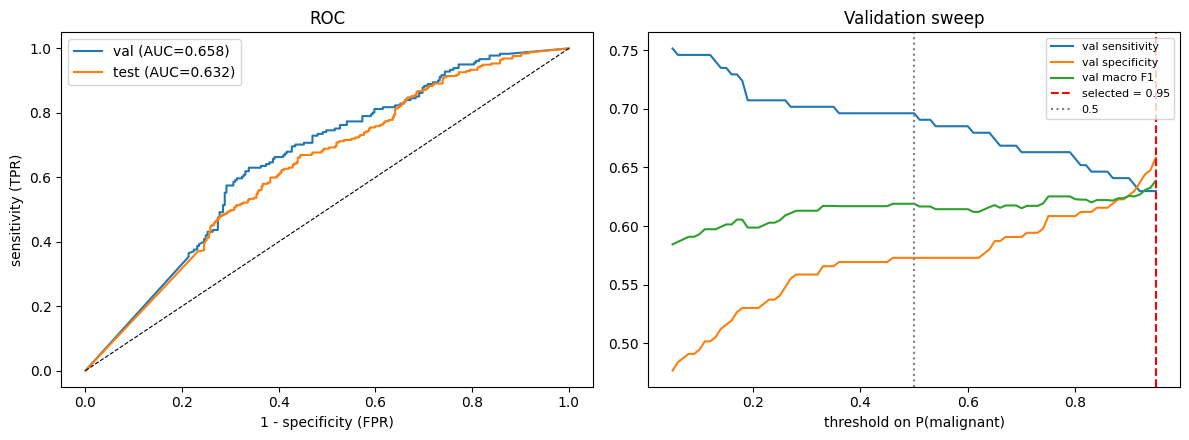

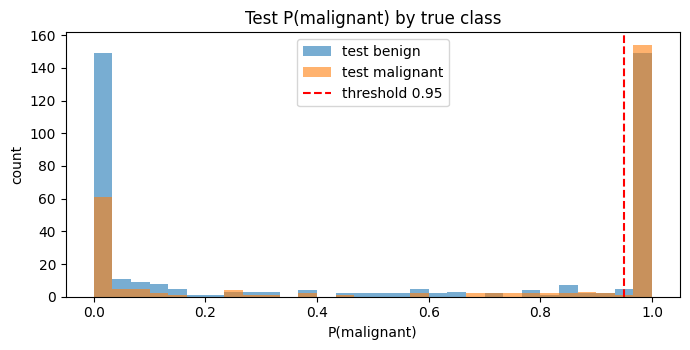

Example reasoning traces (validation):

[val #0] patient=P_00045 pathology=MALIGNANT kind=mass
  gold: shape=unknown margin=other calc=absent kind=mass
  image: /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/jpeg/1.3.6.1.4.1.9590.100.1.2.31764380412808876606254242891696464260/2-018.jpg
  P(malignant) = 1.000
  P(kind_mass) = 0.000
  P(kind_calc) = 1.000
  P(shape_irregular) = 0.000
  P(margin_spiculated) = 0.000
  P(calc_suspicious) = 1.000
  query P(malignant) = 1.000  (this is the decision score)
  rule-body products, explanation only: mass&irregular=0.000  mass&spiculated=0.000  calc&suspicious=1.000
  largest rule body: calcification & suspicious calc = 1.000
  decision @ 0.95: MALIGNANT  (gold MALIGNANT) -> correct

[val #1] patient=P_00045 pathology=MALIGNANT kind=mass
  gold: shape=unknown margin=other calc=absent kind=mass
  image: /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/jpeg/1.3.6.1.4.1.9590.100.1.2.342806866711097390303497745

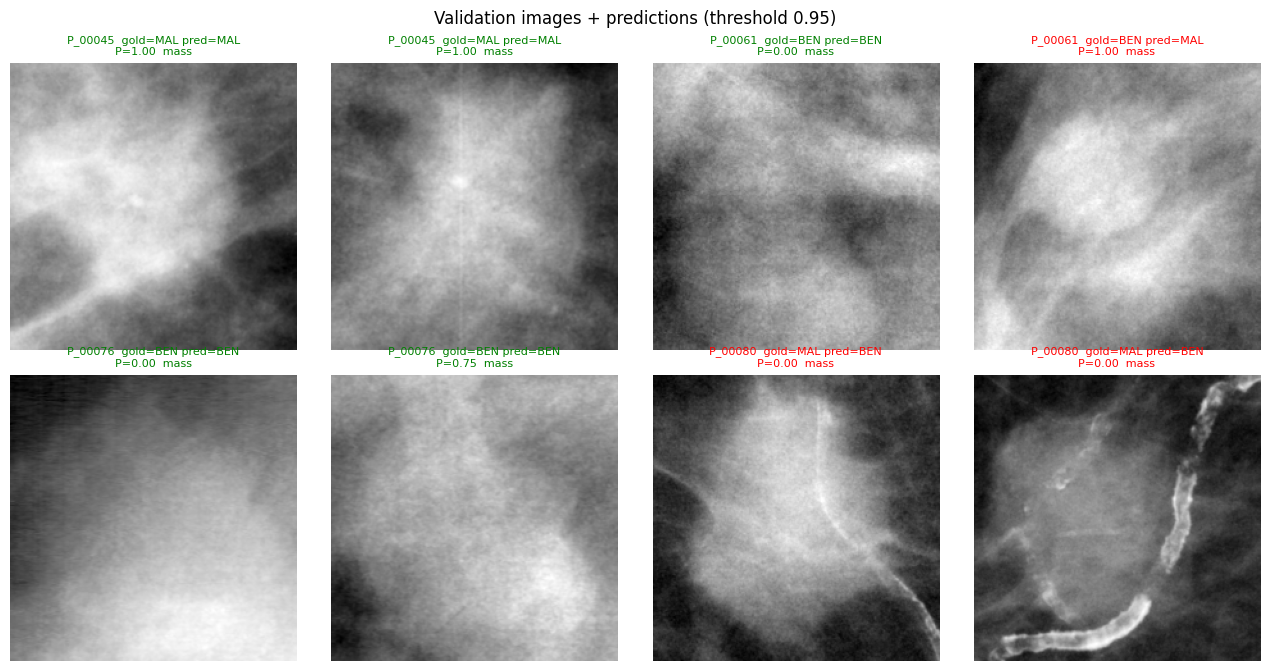

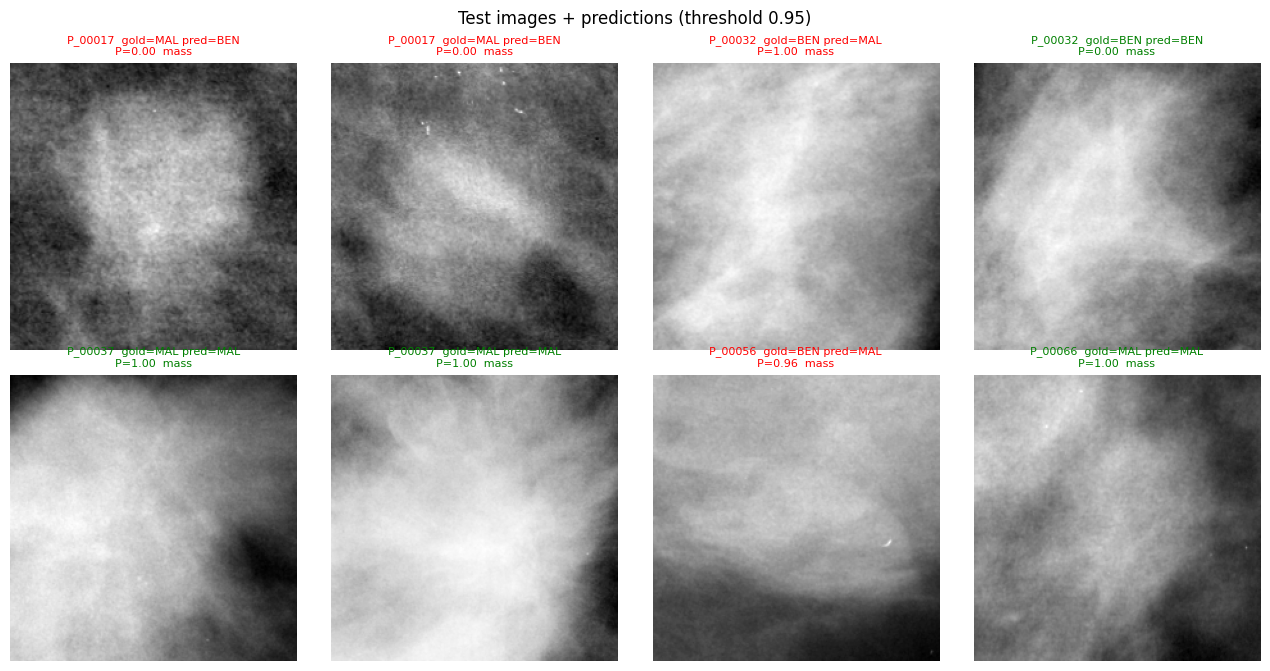

In [14]:
def extract_prob(result):
    if result is None:
        return 0.0
    mapping = result.result if hasattr(result, "result") else (result if isinstance(result, dict) else {})
    if not mapping:
        return 0.0
    vals = []
    for v in mapping.values():
        if hasattr(v, "detach"):
            vals.append(float(v.detach().cpu().item() if v.numel() == 1 else v.detach().cpu().mean()))
        else:
            vals.append(float(v))
    return float(sum(vals) / len(vals))


def malignant_probability(split_name, i):
    q = Query(Term("malignant", Term("tensor", Term(split_name, Constant(i)))))
    solved = model.solve([q])
    return extract_prob(solved[0]) if solved else 0.0


def _f1(tp, fp, fn):
    prec = tp / max(tp + fp, 1)
    rec = tp / max(tp + fn, 1)
    if prec + rec == 0:
        return 0.0
    return 2.0 * prec * rec / (prec + rec)


def collect_probs(name, dataset, df):
    """Run the malignant(X) query once per image. Expensive, so do it once per split."""
    y_true, y_prob = [], []
    for i in tqdm(range(len(dataset)), desc=f"Scoring {name}", unit="img"):
        y_true.append(int(df.iloc[i]["malignant"]))
        y_prob.append(malignant_probability(name, i))
    return np.array(y_true), np.array(y_prob)


def metrics_at(name, y_true, y_prob, thr):
    """All metrics for one split at one decision threshold."""
    y_pred = (y_prob >= thr).astype(int)
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    tn = int(((y_pred == 0) & (y_true == 0)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    precision = tp / max(tp + fp, 1)
    f1_mal = _f1(tp, fp, fn)
    f1_ben = _f1(tn, fn, fp)
    try:
        auc = float(roc_auc_score(y_true, y_prob)) if len(np.unique(y_true)) == 2 else float("nan")
    except Exception:
        auc = float("nan")
    return {
        "split": name, "threshold": float(thr), "n": int(len(y_true)),
        "accuracy": (tp + tn) / max(len(y_true), 1),
        "precision": precision,
        "sensitivity": tp / max(tp + fn, 1),
        "specificity": tn / max(tn + fp, 1),
        "f1_malignant": f1_mal,
        "f1_benign": f1_ben,
        "f1_macro": 0.5 * (f1_mal + f1_ben),
        "roc_auc": auc,
        "tp": tp, "tn": tn, "fp": fp, "fn": fn,
        "mean_p": float(y_prob.mean()),
        "pct_pred_malignant": float(y_pred.mean()),
    }


def choose_threshold(y_true, y_prob, mode, target_sens=0.80, fixed=0.5):
    """Pick the decision threshold on VALIDATION probabilities only.

    Returns (threshold, sweep_dataframe). The sweep is kept so the choice is
    visible: every candidate threshold with its sensitivity/specificity/F1.
    """
    grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
    sweep = pd.DataFrame([metrics_at("val", y_true, y_prob, t) for t in grid])
    sweep["youden_j"] = sweep["sensitivity"] + sweep["specificity"] - 1.0
    if mode == "fixed":
        return float(fixed), sweep
    if mode == "youden":
        return float(sweep.loc[sweep["youden_j"].idxmax(), "threshold"]), sweep
    if mode == "f1_macro":
        return float(sweep.loc[sweep["f1_macro"].idxmax(), "threshold"]), sweep
    if mode == "target_sensitivity":
        ok = sweep[sweep["sensitivity"] >= target_sens]
        if len(ok) == 0:
            print(f"No threshold reaches sensitivity >= {target_sens}; falling back to Youden's J.")
            return float(sweep.loc[sweep["youden_j"].idxmax(), "threshold"]), sweep
        # Highest specificity among thresholds that reach the sensitivity target.
        # Ties keep the first row. The grid is ascending, so that is the lowest tied threshold.
        print("Threshold rule: highest validation specificity with sensitivity >= target. Ties keep the lowest threshold.")
        return float(ok.loc[ok["specificity"].idxmax(), "threshold"]), sweep
    raise ValueError(f"Unknown THRESHOLD_MODE={mode!r}")


from sklearn.metrics import roc_auc_score, roc_curve

y_val_true, val_prob = collect_probs("val", val_set, df_val)
y_test_true, test_prob = collect_probs("test", test_set, df_test)
np.save(OUTPUT_DIR / "y_test_true.npy", np.asarray(y_test_true))
print("Saved test labels for CI without retraining:", OUTPUT_DIR / "y_test_true.npy")

SELECTED_THRESHOLD, val_sweep = choose_threshold(
    y_val_true, val_prob, THRESHOLD_MODE, target_sens=TARGET_SENSITIVITY, fixed=DECISION_THRESHOLD
)
print(f"\nTHRESHOLD_MODE={THRESHOLD_MODE!r} -> selected threshold on validation = {SELECTED_THRESHOLD:.2f}")
print("(chosen on validation only; test uses the same value unchanged)\n")

# How the choice would differ under each rule — useful when writing the paper.
alt = {
    "fixed 0.5": 0.5,
    "youden": float(val_sweep.loc[val_sweep["youden_j"].idxmax(), "threshold"]),
    "f1_macro": float(val_sweep.loc[val_sweep["f1_macro"].idxmax(), "threshold"]),
    f"target_sensitivity>={TARGET_SENSITIVITY}": SELECTED_THRESHOLD if THRESHOLD_MODE == "target_sensitivity"
        else choose_threshold(y_val_true, val_prob, "target_sensitivity", TARGET_SENSITIVITY)[0],
}
rows = []
for rule, thr in alt.items():
    for split, yt, yp in (("val", y_val_true, val_prob), ("test", y_test_true, test_prob)):
        m = metrics_at(split, yt, yp, thr)
        rows.append({"rule": rule, **m})
compare_df = pd.DataFrame(rows)[["rule", "threshold", "split", "accuracy", "sensitivity", "specificity",
                                  "precision", "f1_malignant", "f1_benign", "f1_macro", "roc_auc", "tp", "tn", "fp", "fn"]]
print("Threshold rules compared (each threshold chosen on val, applied to test):")
display(compare_df.round(3))

# Final numbers: at 0.5 (reference) and at the selected threshold.
metrics_val_05 = metrics_at("val", y_val_true, val_prob, 0.5)
metrics_test_05 = metrics_at("test", y_test_true, test_prob, 0.5)
metrics_val = metrics_at("val", y_val_true, val_prob, SELECTED_THRESHOLD)
metrics_test = metrics_at("test", y_test_true, test_prob, SELECTED_THRESHOLD)
metrics_df = pd.DataFrame([metrics_val_05, metrics_test_05, metrics_val, metrics_test])
print("\nReference (0.5) vs selected threshold:")
display(metrics_df.round(3))
print(
    "If the model predicts only one class: specificity or sensitivity hits 0, "
    "f1_benign or f1_malignant hits 0, and f1_macro stays low even if accuracy looks ok. "
    "ROC-AUC does not depend on the threshold, so it tells you how good the ranking itself is."
)
if SMOKE_TEST:
    print("SMOKE_TEST=True: this is a tiny wiring test. Treat the numbers as a smoke-test check only.")

# Dual operating points for the paper: primary (THRESHOLD_MODE) + val macro-F1.
dpl_thr_f1 = float(val_sweep.loc[val_sweep["f1_macro"].idxmax(), "threshold"])
dual_ops = pd.DataFrame([
    {"role": "primary (THRESHOLD_MODE)", **metrics_at("test", y_test_true, test_prob, SELECTED_THRESHOLD)},
    {"role": "balanced (val macro-F1)", **metrics_at("test", y_test_true, test_prob, dpl_thr_f1)},
    {"role": "reference (fixed 0.5)", **metrics_at("test", y_test_true, test_prob, 0.5)},
])
print("\nDual DeepProbLog operating points (TEST):")
display(dual_ops.round(3))


# Visual: ROC curves + validation sensitivity/specificity vs threshold.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for split, yt, yp in (("val", y_val_true, val_prob), ("test", y_test_true, test_prob)):
    if len(np.unique(yt)) == 2:
        fpr, tpr, _ = roc_curve(yt, yp)
        axes[0].plot(fpr, tpr, label=f"{split} (AUC={roc_auc_score(yt, yp):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set_xlabel("1 - specificity (FPR)"); axes[0].set_ylabel("sensitivity (TPR)"); axes[0].set_title("ROC")
axes[0].legend()
axes[1].plot(val_sweep["threshold"], val_sweep["sensitivity"], label="val sensitivity")
axes[1].plot(val_sweep["threshold"], val_sweep["specificity"], label="val specificity")
axes[1].plot(val_sweep["threshold"], val_sweep["f1_macro"], label="val macro F1")
axes[1].axvline(SELECTED_THRESHOLD, color="red", ls="--", label=f"selected = {SELECTED_THRESHOLD:.2f}")
axes[1].axvline(0.5, color="gray", ls=":", label="0.5")
axes[1].set_xlabel("threshold on P(malignant)"); axes[1].set_title("Validation sweep")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

# Histogram of P(malignant) by true class: shows whether the two classes separate at all.
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(test_prob[y_test_true == 0], bins=30, alpha=0.6, label="test benign")
ax.hist(test_prob[y_test_true == 1], bins=30, alpha=0.6, label="test malignant")
ax.axvline(SELECTED_THRESHOLD, color="red", ls="--", label=f"threshold {SELECTED_THRESHOLD:.2f}")
ax.set_xlabel("P(malignant)"); ax.set_ylabel("count"); ax.legend()
ax.set_title("Test P(malignant) by true class")
fig.tight_layout()
plt.show()


def inspect_case(split_name, df, i, thr=None):
    """Print the full reasoning trace for one image.

    This is the DeepProbLog explanation: the final P(malignant) is computed
    from the concept probabilities through the three rules in the .pl program,
    so you can see WHICH rule fired and WHICH concept drove the decision.
    """
    thr = SELECTED_THRESHOLD if thr is None else thr
    row = df.iloc[i]
    img = Term("tensor", Term(split_name, Constant(i)))
    queries = {
        "malignant": Query(Term("malignant", img)),
        "kind_mass": Query(Term("lesion_kind", img, Term("mass"))),
        "kind_calc": Query(Term("lesion_kind", img, Term("calcification"))),
        "shape_irregular": Query(Term("shape", img, Term("irregular"))),
        "margin_spiculated": Query(Term("margin", img, Term("spiculated"))),
        "calc_suspicious": Query(Term("calc", img, Term("suspicious"))),
    }
    p = {}
    for name, q in queries.items():
        solved = model.solve([q])
        p[name] = extract_prob(solved[0]) if solved else 0.0
    gold = "MALIGNANT" if int(row["malignant"]) == 1 else "BENIGN"
    pred = "MALIGNANT" if p["malignant"] >= thr else "BENIGN"
    verdict = "correct" if gold == pred else "WRONG"
    print(f"\n[{split_name} #{i}] patient={row['patient_id']} pathology={row['pathology']} kind={row['abnormality_kind']}")
    print(f"  gold: shape={row['shape_concept']} margin={row['margin_concept']} calc={row['calc_concept']} kind={row.get('kind_concept')}")
    if "resolved_path" in row.index:
        print(f"  image: {row['resolved_path']}")
    for name, v in p.items():
        print(f"  P({name}) = {v:.3f}")
    # Rule-body products are an explanation. They are not the decision.
    # The mass rules share lesion_kind, so the query probability is not their maximum.
    r1 = p["kind_mass"] * p["shape_irregular"]
    r2 = p["kind_mass"] * p["margin_spiculated"]
    r3 = p["kind_calc"] * p["calc_suspicious"]
    top = max((("mass & irregular shape", r1), ("mass & spiculated margin", r2), ("calcification & suspicious calc", r3)),
              key=lambda kv: kv[1])
    print(f"  query P(malignant) = {p['malignant']:.3f}  (this is the decision score)")
    print(f"  rule-body products, explanation only: mass&irregular={r1:.3f}  mass&spiculated={r2:.3f}  calc&suspicious={r3:.3f}")
    print(f"  largest rule body: {top[0]} = {top[1]:.3f}")
    print(f"  decision @ {thr:.2f}: {pred}  (gold {gold}) -> {verdict}")


print("Example reasoning traces (validation):")
for i in range(min(3, len(val_set))):
    inspect_case("val", df_val, i)

# Also show the traces the paper needs most: a false negative and a false positive on test.
y_test_pred = (test_prob >= SELECTED_THRESHOLD).astype(int)
fn_idx = np.where((y_test_pred == 0) & (y_test_true == 1))[0]
fp_idx = np.where((y_test_pred == 1) & (y_test_true == 0))[0]
if len(fn_idx):
    print("\nExample FALSE NEGATIVE on test (missed cancer — the case that matters most):")
    inspect_case("test", df_test, int(fn_idx[0]))
if len(fp_idx):
    print("\nExample FALSE POSITIVE on test:")
    inspect_case("test", df_test, int(fp_idx[0]))


def gold_concept_prob(split_name, i, predicate, label):
    q = Query(Term(predicate, Term("tensor", Term(split_name, Constant(i))), Term(label)))
    solved = model.solve([q])
    return extract_prob(solved[0]) if solved else 0.0


print("\nValidation concept check (mean P(gold label); >0.5 means the net usually agrees with the CSV):")
concept_check = {}
for pred, col in (
    ("lesion_kind", "kind_concept"),
    ("shape", "shape_concept"),
    ("margin", "margin_concept"),
    ("calc", "calc_concept"),
):
    probs = [gold_concept_prob("val", i, pred, df_val.iloc[i][col]) for i in range(len(df_val))]
    arr = np.array(probs)
    concept_check[pred] = {"mean_p_gold": float(arr.mean()), "agree_at_0.5": float((arr >= 0.5).mean())}
    print(f"  {pred:12s}  mean P(gold)={arr.mean():.3f}  agree@0.5={(arr >= 0.5).mean():.3f}")


def show_prediction_grid(title, df, tensors, y_prob, n=None, thr=None):
    thr = SELECTED_THRESHOLD if thr is None else thr
    n = min(int(n if n is not None else SHOW_N_IMAGES), len(df), len(tensors))
    y_pred = (np.asarray(y_prob) >= thr).astype(int)
    cols = 4
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(13, 3.4 * rows))
    axes = np.atleast_1d(axes).ravel()
    for i in range(n):
        ax = axes[i]
        ax.imshow(tensor_to_numpy(tensors[i]), cmap="gray")
        row = df.iloc[i]
        gold = "MAL" if int(row["malignant"]) == 1 else "BEN"
        pred = "MAL" if int(y_pred[i]) == 1 else "BEN"
        ok = gold == pred
        ax.set_title(
            f"{row['patient_id']}  gold={gold} pred={pred}\nP={y_prob[i]:.2f}  {row['abnormality_kind']}",
            fontsize=8,
            color=("green" if ok else "red"),
        )
        ax.axis("off")
    for j in range(n, len(axes)):
        axes[j].axis("off")
    fig.suptitle(f"{title} (threshold {thr:.2f})")
    fig.tight_layout()
    plt.show()


print(f"\nPredicted test / validation images at threshold {SELECTED_THRESHOLD:.2f} (green = match, red = mismatch):")
show_prediction_grid("Validation images + predictions", df_val, val_tensors, val_prob)
show_prediction_grid("Test images + predictions", df_test, test_tensors, test_prob)


## 11a) Stage 1 alone versus Stage 2

Stage 1 probabilities were saved before the DeepProbLog epochs. This cell applies the same validation threshold rule to those probabilities and prints the comparison. It does not train anything and does not change `SELECTED_THRESHOLD`.


In [15]:

print("\nSTAGE 1 ALONE VERSUS STAGE 2")
print("Stage 1 is scored after concept warm-up and before the DeepProbLog epochs.")
print("Stage 2 is the model after those epochs. The decision score in both rows is the query probability.")
print("Each stage chooses its own validation threshold with the same rule.")
print("This cell does not replace SELECTED_THRESHOLD. That name remains the Stage 2 threshold.")

try:
    s1_val = np.asarray(stage1_val_prob, dtype=float)
    s1_test = np.asarray(stage1_test_prob, dtype=float)
    print("Using Stage 1 probabilities scored in this run.")
except NameError:
    s1_val_path = OUTPUT_DIR / "stage1_val_prob.npy"
    s1_test_path = OUTPUT_DIR / "stage1_test_prob.npy"
    if not s1_val_path.is_file() or not s1_test_path.is_file():
        raise RuntimeError(
            "Stage 1 probabilities are missing. Training resumed from a checkpoint, so Stage 1 was not scored. "
            "Delete checkpoints/final_model_checkpoint_*.pt and run from the training cell."
        )
    s1_val = np.load(s1_val_path)
    s1_test = np.load(s1_test_path)
    print("Loaded Stage 1 probabilities from the saved npy files.")

y1_val = df_val["malignant"].astype(int).to_numpy()
y1_test = df_test["malignant"].astype(int).to_numpy()
if len(s1_val) != len(y1_val) or len(s1_test) != len(y1_test):
    raise RuntimeError(
        f"Stage 1 length mismatch: val {len(s1_val)} vs {len(y1_val)}, test {len(s1_test)} vs {len(y1_test)}."
    )

print("\nChoosing the Stage 1 threshold on Stage 1 validation scores only.")
stage1_threshold, _stage1_sweep = choose_threshold(
    y1_val, s1_val, THRESHOLD_MODE, target_sens=TARGET_SENSITIVITY, fixed=DECISION_THRESHOLD
)
print(f"Stage 1 threshold = {stage1_threshold:.2f}")
print(f"Stage 2 threshold (SELECTED_THRESHOLD) = {SELECTED_THRESHOLD:.2f}")

stage_rows = []
for stage, yt_val, yp_val, yt_test, yp_test, thr in (
    ("stage1", y1_val, s1_val, y1_test, s1_test, stage1_threshold),
    ("stage2", y_val_true, val_prob, y_test_true, test_prob, SELECTED_THRESHOLD),
):
    for rule, rule_thr in (
        ("fixed 0.5", 0.5),
        (f"target_sensitivity>={TARGET_SENSITIVITY}", thr),
    ):
        for split, yt, yp in (("val", yt_val, yp_val), ("test", yt_test, yp_test)):
            stage_rows.append({"stage": stage, "rule": rule, **metrics_at(split, yt, yp, rule_thr)})

stage_compare_df = pd.DataFrame(stage_rows)
stage_cols = [
    "stage", "rule", "split", "threshold", "n", "accuracy", "sensitivity", "specificity",
    "precision", "f1_macro", "roc_auc", "tp", "tn", "fp", "fn",
]
stage_compare_df = stage_compare_df[stage_cols]
stage_compare_df.to_csv(OUTPUT_DIR / "stage1_vs_stage2.csv", index=False)
print("\nStage 1 versus Stage 2:")
print(stage_compare_df.round(3).to_string(index=False))
display(stage_compare_df.round(3))

rule_name = f"target_sensitivity>={TARGET_SENSITIVITY}"
s1_test_row = stage_compare_df[
    (stage_compare_df["stage"] == "stage1")
    & (stage_compare_df["split"] == "test")
    & (stage_compare_df["rule"] == rule_name)
].iloc[0]
s2_test_row = stage_compare_df[
    (stage_compare_df["stage"] == "stage2")
    & (stage_compare_df["split"] == "test")
    & (stage_compare_df["rule"] == rule_name)
].iloc[0]
print("\nTest difference, Stage 2 minus Stage 1, at each stage's own validation threshold:")
for key in ("roc_auc", "accuracy", "sensitivity", "specificity", "f1_macro"):
    delta = float(s2_test_row[key]) - float(s1_test_row[key])
    print(f"  {key}: stage1 {float(s1_test_row[key]):.3f}  stage2 {float(s2_test_row[key]):.3f}  delta {delta:+.3f}")
print("ROC-AUC does not use the threshold. The other four numbers do.")
print("Saved and printed:", OUTPUT_DIR / "stage1_vs_stage2.csv")



STAGE 1 ALONE VERSUS STAGE 2
Stage 1 is scored after concept warm-up and before the DeepProbLog epochs.
Stage 2 is the model after those epochs. The decision score in both rows is the query probability.
Each stage chooses its own validation threshold with the same rule.
This cell does not replace SELECTED_THRESHOLD. That name remains the Stage 2 threshold.
Using Stage 1 probabilities scored in this run.

Choosing the Stage 1 threshold on Stage 1 validation scores only.
Threshold rule: highest validation specificity with sensitivity >= target. Ties keep the lowest threshold.
Stage 1 threshold = 0.13
Stage 2 threshold (SELECTED_THRESHOLD) = 0.95

Stage 1 versus Stage 2:
 stage                    rule split  threshold   n  accuracy  sensitivity  specificity  precision  f1_macro  roc_auc  tp  tn  fp  fn
stage1               fixed 0.5   val       0.50 462     0.667        0.630        0.690      0.567     0.656    0.720 114 194  87  67
stage1               fixed 0.5  test       0.50 644   

,stage,rule,split,threshold,n,accuracy,sensitivity,specificity,precision,f1_macro,roc_auc,tp,tn,fp,fn
0,stage1,fixed 0.5,val,0.50,462,0.667,0.630,0.690,0.567,0.656,0.720,114,194,87,67
1,stage1,fixed 0.5,test,0.50,644,0.641,0.661,0.628,0.541,0.637,0.696,170,243,144,87
2,stage1,target_sensitivity>=0.8,val,0.13,462,0.630,0.801,0.520,0.518,0.630,0.720,145,146,135,36
3,stage1,target_sensitivity>=0.8,test,0.13,644,0.585,0.794,0.447,0.488,0.584,0.696,204,173,214,53
4,stage2,fixed 0.5,val,0.50,462,0.621,0.696,0.573,0.512,0.619,0.658,126,161,120,55
5,stage2,fixed 0.5,test,0.50,644,0.582,0.677,0.519,0.483,0.582,0.632,174,201,186,83
6,stage2,target_sensitivity>=0.8,val,0.95,462,0.647,0.630,0.658,0.543,0.639,0.658,114,185,96,67
7,stage2,target_sensitivity>=0.8,test,0.95,644,0.602,0.599,0.605,0.502,0.596,0.632,154,234,153,103



Test difference, Stage 2 minus Stage 1, at each stage's own validation threshold:
  roc_auc: stage1 0.696  stage2 0.632  delta -0.064
  accuracy: stage1 0.585  stage2 0.602  delta +0.017
  sensitivity: stage1 0.794  stage2 0.599  delta -0.195
  specificity: stage1 0.447  stage2 0.605  delta +0.158
  f1_macro: stage1 0.584  stage2 0.596  delta +0.012
ROC-AUC does not use the threshold. The other four numbers do.
Saved and printed: /kaggle/working/processed/stage1_vs_stage2.csv


## 11b) Pure ResNet18 malignant/benign baseline (no DeepProbLog)

**What:** train an ImageNet ResNet18 that maps the same ROI tensors directly to malignant vs benign, on the same patient-disjoint splits.

**Why:** the paper needs a fair accuracy reference. DeepProbLog's value is the inspectable concept→rule path; the baseline shows what the same backbone reaches without symbolic reasoning.


In [16]:
class MalignantResNet(nn.Module):
    """End-to-end ResNet18 binary classifier (paper baseline)."""

    def __init__(self, pretrained=True):
        super().__init__()
        weights = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        net = models.resnet18(weights=weights)
        net.fc = nn.Linear(net.fc.in_features, 2)
        self.net = net
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x, return_prob=True):
        x = _prepare_input(x, next(self.parameters()).device, three_channel=True)
        logits = self.net(x)
        return self.softmax(logits) if return_prob else logits


def _baseline_metrics(y_true, y_prob, thr=0.5):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    y_pred = (y_prob >= thr).astype(int)
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    tn = int(((y_pred == 0) & (y_true == 0)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    f1_mal = 0.0 if (tp + fp) == 0 or (tp + fn) == 0 else (2 * tp / (2 * tp + fp + fn))
    f1_ben = 0.0 if (tn + fn) == 0 or (tn + fp) == 0 else (2 * tn / (2 * tn + fn + fp))
    try:
        auc = float(roc_auc_score(y_true, y_prob)) if len(np.unique(y_true)) == 2 else float("nan")
    except Exception:
        auc = float("nan")
    return {
        "accuracy": (tp + tn) / max(len(y_true), 1),
        "sensitivity": tp / max(tp + fn, 1),
        "specificity": tn / max(tn + fp, 1),
        "precision": tp / max(tp + fp, 1),
        "f1_malignant": f1_mal,
        "f1_benign": f1_ben,
        "f1_macro": 0.5 * (f1_mal + f1_ben),
        "roc_auc": auc,
        "tp": tp, "tn": tn, "fp": fp, "fn": fn,
        "threshold": float(thr),
    }


baseline_metrics = None
if RUN_NEURAL_BASELINE:
    from torch.utils.data import TensorDataset, DataLoader as TorchLoader

    print(f"Training pure ResNet18 baseline for {BASELINE_EPOCHS} epochs "
          f"(same tensors / splits as DeepProbLog)...")
    y_train = torch.tensor(df_train["malignant"].astype(int).values, dtype=torch.long)
    # train_tensors may live on CUDA; DataLoader prefers CPU storage
    x_train = torch.stack([t.detach().cpu() if t.is_cuda else t.cpu() for t in train_tensors])
    train_ds = TensorDataset(x_train, y_train)
    train_loader = TorchLoader(train_ds, batch_size=max(BATCH_SIZE, 8), shuffle=True)

    baseline = MalignantResNet(pretrained=True).to(DEVICE)
    # freeze trunk briefly then fine-tune
    for p in baseline.net.parameters():
        p.requires_grad = False
    for p in baseline.net.fc.parameters():
        p.requires_grad = True
    opt = torch.optim.Adam(baseline.net.fc.parameters(), lr=LR)
    crit = nn.CrossEntropyLoss()

    t0 = time.perf_counter()
    for ep in range(BASELINE_EPOCHS):
        if ep == min(2, BASELINE_EPOCHS - 1) and ep > 0:
            for p in baseline.net.parameters():
                p.requires_grad = True
            opt = torch.optim.Adam(
                [
                    {"params": [p for n, p in baseline.net.named_parameters() if not n.startswith("fc.")],
                     "lr": LR * BACKBONE_LR_MULT},
                    {"params": baseline.net.fc.parameters(), "lr": LR},
                ]
            )
            print(f"  baseline: unfroze trunk at epoch {ep + 1}")
        baseline.train()
        total_loss, n = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            logits = baseline(xb, return_prob=False)
            loss = crit(logits, yb)
            loss.backward()
            opt.step()
            total_loss += float(loss.item()) * len(yb)
            n += len(yb)
        print(f"  baseline epoch {ep + 1}/{BASELINE_EPOCHS}  loss={total_loss / max(n, 1):.4f}")

    @torch.no_grad()
    def score_split(tensors, df):
        baseline.eval()
        probs = []
        for t in tensors:
            p = baseline(t.unsqueeze(0) if t.dim() == 3 else t)
            probs.append(float(p[0, 1].detach().cpu()))
        y = df["malignant"].astype(int).values
        return _baseline_metrics(y, probs, thr=0.5), np.array(probs)

    base_val, base_val_prob = score_split(val_tensors, df_val)
    base_test, base_test_prob = score_split(test_tensors, df_test)
    y_base_val = df_val["malignant"].astype(int).values
    y_base_test = df_test["malignant"].astype(int).values

    # Fair comparison: also pick a high-sensitivity threshold on VAL for the baseline
    # (same TARGET_SENSITIVITY protocol as DeepProbLog), then apply to test.
    base_thr_sens, base_sweep = choose_threshold(
        y_base_val, base_val_prob, "target_sensitivity",
        target_sens=TARGET_SENSITIVITY, fixed=0.5,
    )
    base_thr_f1 = float(base_sweep.loc[base_sweep["f1_macro"].idxmax(), "threshold"])
    base_thr_youden = float(base_sweep.loc[base_sweep["youden_j"].idxmax(), "threshold"])

    baseline_rows = []
    for rule, thr in (
        ("fixed 0.5", 0.5),
        (f"target_sensitivity>={TARGET_SENSITIVITY}", base_thr_sens),
        ("f1_macro", base_thr_f1),
        ("youden", base_thr_youden),
    ):
        for split, yt, yp in (
            ("val", y_base_val, base_val_prob),
            ("test", y_base_test, base_test_prob),
        ):
            baseline_rows.append({"rule": rule, "split": split, **_baseline_metrics(yt, yp, thr=thr)})
    baseline_compare_df = pd.DataFrame(baseline_rows)

    baseline_metrics = {
        "val_at_0.5": base_val,
        "test_at_0.5": base_test,
        "val": _baseline_metrics(y_base_val, base_val_prob, thr=base_thr_sens),
        "test": _baseline_metrics(y_base_test, base_test_prob, thr=base_thr_sens),
        "selected_threshold_sens": float(base_thr_sens),
        "selected_threshold_f1_macro": float(base_thr_f1),
    }
    print(f"Baseline finished in {(time.perf_counter() - t0) / 60:.1f} min")
    print("Baseline threshold rules (val-chosen, applied to test):")
    display(baseline_compare_df.round(3))
    print(f"Baseline high-sens threshold (val sens>={TARGET_SENSITIVITY}): {base_thr_sens:.2f}")
    torch.save(baseline.state_dict(), OUTPUT_DIR / "resnet18_malignant_baseline.pt")
    np.save(OUTPUT_DIR / "baseline_val_prob.npy", base_val_prob)
    np.save(OUTPUT_DIR / "baseline_test_prob.npy", base_test_prob)
    baseline_compare_df.to_csv(OUTPUT_DIR / "baseline_threshold_rules_comparison.csv", index=False)
    print("Saved:", OUTPUT_DIR / "resnet18_malignant_baseline.pt")
else:
    print("RUN_NEURAL_BASELINE=False — skipping pure ResNet18 baseline.")
    baseline_compare_df = None


Training pure ResNet18 baseline for 15 epochs (same tensors / splits as DeepProbLog)...
  baseline epoch 1/15  loss=0.6538
  baseline epoch 2/15  loss=0.6232
  baseline: unfroze trunk at epoch 3
  baseline epoch 3/15  loss=0.5870
  baseline epoch 4/15  loss=0.4489
  baseline epoch 5/15  loss=0.3149
  baseline epoch 6/15  loss=0.2229
  baseline epoch 7/15  loss=0.1848
  baseline epoch 8/15  loss=0.1472
  baseline epoch 9/15  loss=0.1369
  baseline epoch 10/15  loss=0.1165
  baseline epoch 11/15  loss=0.1181
  baseline epoch 12/15  loss=0.1060
  baseline epoch 13/15  loss=0.0939
  baseline epoch 14/15  loss=0.0941
  baseline epoch 15/15  loss=0.0759
No threshold reaches sensitivity >= 0.8; falling back to Youden's J.
Baseline finished in 8.5 min
Baseline threshold rules (val-chosen, applied to test):


,rule,split,accuracy,sensitivity,specificity,precision,f1_malignant,f1_benign,f1_macro,roc_auc,tp,tn,fp,fn,threshold
0,fixed 0.5,val,0.703,0.392,0.904,0.724,0.509,0.788,0.648,0.790,71,254,27,110,0.50
1,fixed 0.5,test,0.680,0.447,0.835,0.642,0.528,0.758,0.643,0.734,115,323,64,142,0.50
2,target_sensitivity>=0.8,val,0.725,0.630,0.786,0.655,0.642,0.777,0.710,0.790,114,221,60,67,0.06
3,target_sensitivity>=0.8,test,0.654,0.661,0.649,0.556,0.604,0.692,0.648,0.734,170,251,136,87,0.06
4,f1_macro,val,0.725,0.630,0.786,0.655,0.642,0.777,0.710,0.790,114,221,60,67,0.06
5,f1_macro,test,0.654,0.661,0.649,0.556,0.604,0.692,0.648,0.734,170,251,136,87,0.06
6,youden,val,0.725,0.630,0.786,0.655,0.642,0.777,0.710,0.790,114,221,60,67,0.06
7,youden,test,0.654,0.661,0.649,0.556,0.604,0.692,0.648,0.734,170,251,136,87,0.06


Baseline high-sens threshold (val sens>=0.8): 0.06
Saved: /kaggle/working/processed/resnet18_malignant_baseline.pt


## 11c) Bootstrap AUC intervals and paired DeLong test

This cell does not train. It uses the test scores already in memory, or `test_prob.npy`, `baseline_test_prob.npy`, and `y_test_true.npy` from the same run.

Bootstrap resamples the same test rows for both models and reports a 95% percentile interval for each AUC. DeLong reports the AUC difference, its 95% interval, and a two-sided p-value. The structural components follow Sun and Xu, and the AUC is checked against sklearn when the cell runs.


In [17]:
import math

def _midrank(scores):
    order = np.argsort(scores, kind="mergesort")
    ordered = np.asarray(scores, dtype=float)[order]
    ranks = np.empty(len(ordered), dtype=float)
    start = 0
    while start < len(ordered):
        stop = start
        while stop < len(ordered) and ordered[stop] == ordered[start]:
            stop += 1
        ranks[start:stop] = 0.5 * (start + stop - 1) + 1
        start = stop
    out = np.empty(len(ordered), dtype=float)
    out[order] = ranks
    return out


def _structural(y_true, scores):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    positive = scores[y_true == 1]
    negative = scores[y_true == 0]
    ranks = _midrank(np.concatenate([positive, negative]))
    rank_pos, rank_neg = ranks[:len(positive)], ranks[len(positive):]
    auc = rank_pos.sum() / (len(positive) * len(negative)) - (len(positive) + 1.0) / (2.0 * len(negative))
    v_pos = (rank_pos - _midrank(positive)) / len(negative)
    v_neg = 1.0 - (rank_neg - _midrank(negative)) / len(positive)
    return float(auc), v_pos, v_neg


def _cov(left, right):
    return float(np.cov(left, right, ddof=1)[0, 1])


def delong_test(y_true, scores_a, scores_b):
    auc_a, vp_a, vn_a = _structural(y_true, scores_a)
    auc_b, vp_b, vn_b = _structural(y_true, scores_b)
    n_pos = int((np.asarray(y_true) == 1).sum())
    n_neg = int((np.asarray(y_true) == 0).sum())
    var = (
        _cov(vp_a, vp_a) / n_pos + _cov(vn_a, vn_a) / n_neg
        + _cov(vp_b, vp_b) / n_pos + _cov(vn_b, vn_b) / n_neg
        - 2 * _cov(vp_a, vp_b) / n_pos - 2 * _cov(vn_a, vn_b) / n_neg
    )
    difference = auc_a - auc_b
    var = max(0.0, var)
    se = math.sqrt(var) if var > 0 else 0.0
    z_value = 0.0 if se == 0 else difference / se
    p_value = float(math.erfc(abs(z_value) / math.sqrt(2.0)))
    z_crit = 1.959963984540054
    return {
        "auc_deepproblog": auc_a,
        "auc_resnet18": auc_b,
        "auc_difference": difference,
        "standard_error": se,
        "z": z_value,
        "p_value": p_value,
        "ci95_low": difference - z_crit * se,
        "ci95_high": difference + z_crit * se,
        "significant_at_0.05": bool(p_value < 0.05),
    }



def _resolve_test_scores():
    """Use this session's test scores, otherwise the saved npy files. No training."""
    names = ("y_test_true", "test_prob", "base_test_prob")
    if all(name in globals() for name in names):
        return (
            np.asarray(y_test_true).astype(int),
            np.asarray(test_prob, dtype=float),
            np.asarray(base_test_prob, dtype=float),
            "this session",
        )
    dpl_path = OUTPUT_DIR / "test_prob.npy"
    base_path = OUTPUT_DIR / "baseline_test_prob.npy"
    y_path = OUTPUT_DIR / "y_test_true.npy"
    if dpl_path.is_file() and base_path.is_file() and y_path.is_file():
        return (
            np.load(y_path).astype(int),
            np.load(dpl_path).astype(float),
            np.load(base_path).astype(float),
            "saved npy files",
        )
    if dpl_path.is_file() and base_path.is_file() and "df_test" in globals() and "malignant" in df_test.columns:
        dpl = np.load(dpl_path).astype(float)
        base = np.load(base_path).astype(float)
        y = df_test["malignant"].astype(int).to_numpy()
        if len(y) == len(dpl) == len(base):
            return y, dpl, base, "saved probabilities with the current test-table labels"
    return None, None, None, None


def bootstrap_auc_intervals(y_true, scores_by_model, n_boot, seed):
    """Percentile bootstrap of ROC-AUC. Both models use the same resampled rows."""
    from sklearn.metrics import roc_auc_score
    y_true = np.asarray(y_true).astype(int)
    point = {}
    for name, scores in scores_by_model.items():
        point[name] = float(roc_auc_score(y_true, np.asarray(scores, dtype=float)))
    rng = np.random.default_rng(seed)
    draws = {name: [] for name in scores_by_model}
    n = len(y_true)
    used = 0
    for _ in range(int(n_boot)):
        idx = rng.integers(0, n, size=n)
        yb = y_true[idx]
        if np.unique(yb).size < 2:
            continue
        used += 1
        for name, scores in scores_by_model.items():
            draws[name].append(float(roc_auc_score(yb, np.asarray(scores, dtype=float)[idx])))
    out = {}
    for name, values in draws.items():
        arr = np.asarray(values, dtype=float)
        low, high = np.quantile(arr, [0.025, 0.975]) if used else (float("nan"), float("nan"))
        out[name] = {
            "auc": point[name],
            "ci95_low": float(low),
            "ci95_high": float(high),
            "n": int(n),
            "n_boot": int(n_boot),
            "n_boot_used": int(used),
        }
    return out


_old_delong = delong_test

y_ci, dpl_scores, resnet_scores, score_source = _resolve_test_scores()
if y_ci is None:
    print("AUC intervals were not computed. Need y_test_true, test_prob, and base_test_prob in this session, or y_test_true.npy, test_prob.npy, and baseline_test_prob.npy from the same run.")
    bootstrap_result = None
    delong_result = None
else:
    if not (len(y_ci) == len(dpl_scores) == len(resnet_scores)):
        raise AssertionError(
            f"DeLong needs the same test rows. lengths y={len(y_ci)} dpl={len(dpl_scores)} resnet={len(resnet_scores)}"
        )
    print(f"Scoring source: {score_source}. n={len(y_ci)}. No model was trained in this cell.")
    bootstrap_result = bootstrap_auc_intervals(
        y_ci,
        {"deepproblog": dpl_scores, "resnet18": resnet_scores},
        n_boot=BOOTSTRAP_N,
        seed=BOOTSTRAP_SEED,
    )
    # The variance expression was checked against the Sun and Xu structural components.
    # The two AUCs were checked against sklearn. That check used synthetic scores, not these patients.
    delong_result = _old_delong(y_ci, dpl_scores, resnet_scores)
    from sklearn.metrics import roc_auc_score
    sklearn_auc = {
        "deepproblog": float(roc_auc_score(y_ci, dpl_scores)),
        "resnet18": float(roc_auc_score(y_ci, resnet_scores)),
    }
    delong_result["sklearn_auc_deepproblog"] = sklearn_auc["deepproblog"]
    delong_result["sklearn_auc_resnet18"] = sklearn_auc["resnet18"]
    delong_result["auc_matches_sklearn"] = bool(
        abs(delong_result["auc_deepproblog"] - sklearn_auc["deepproblog"]) < 1e-8
        and abs(delong_result["auc_resnet18"] - sklearn_auc["resnet18"]) < 1e-8
    )
    print("\nBootstrap 95% CI for each test AUC")
    for name, row in bootstrap_result.items():
        print(
            f"  {name}: AUC {row['auc']:.3f}  "
            f"95% CI [{row['ci95_low']:.3f}, {row['ci95_high']:.3f}]  "
            f"resamples {row['n_boot_used']}/{row['n_boot']}"
        )
    print("\nPaired DeLong test, DeepProbLog minus ResNet18")
    print(f"  AUC difference {delong_result['auc_difference']:.3f}")
    print(f"  95% CI [{delong_result['ci95_low']:.3f}, {delong_result['ci95_high']:.3f}]")
    print(f"  standard error {delong_result['standard_error']:.3f}  z {delong_result['z']:.3f}  p {delong_result['p_value']:.4g}")
    print(f"  DeLong AUC matches sklearn: {delong_result['auc_matches_sklearn']}")
    if delong_result["p_value"] < 0.05:
        print("The AUC difference is significant at 0.05.")
    else:
        print("The AUC difference is not significant at 0.05.")
    boot_rows = []
    for name, row in bootstrap_result.items():
        boot_rows.append({"model": name, **row})
    boot_df = pd.DataFrame(boot_rows)
    boot_df.to_csv(OUTPUT_DIR / "auc_bootstrap_ci.csv", index=False)
    (OUTPUT_DIR / "auc_bootstrap_ci.json").write_text(json.dumps(bootstrap_result, indent=2))
    (OUTPUT_DIR / "delong_test.json").write_text(json.dumps(delong_result, indent=2))
    print("Saved", OUTPUT_DIR / "auc_bootstrap_ci.csv")
    print("Saved", OUTPUT_DIR / "auc_bootstrap_ci.json")
    print("Saved", OUTPUT_DIR / "delong_test.json")
    print(boot_df.round(3).to_string(index=False))
    print(json.dumps(delong_result, indent=2))


Scoring source: this session. n=644. No model was trained in this cell.

Bootstrap 95% CI for each test AUC
  deepproblog: AUC 0.632  95% CI [0.591, 0.675]  resamples 2000/2000
  resnet18: AUC 0.734  95% CI [0.696, 0.772]  resamples 2000/2000

Paired DeLong test, DeepProbLog minus ResNet18
  AUC difference -0.102
  95% CI [-0.151, -0.052]
  standard error 0.025  z -4.037  p 5.403e-05
  DeLong AUC matches sklearn: True
The AUC difference is significant at 0.05.
Saved /kaggle/working/processed/auc_bootstrap_ci.csv
Saved /kaggle/working/processed/auc_bootstrap_ci.json
Saved /kaggle/working/processed/delong_test.json
      model   auc  ci95_low  ci95_high   n  n_boot  n_boot_used
deepproblog 0.632     0.591      0.675 644    2000         2000
   resnet18 0.734     0.696      0.772 644    2000         2000
{
  "auc_deepproblog": 0.6323711278014057,
  "auc_resnet18": 0.7341215978443378,
  "auc_difference": -0.10175047004293214,
  "standard_error": 0.025201564615796063,
  "z": -4.037466387271

## 13) Save weights and metrics

**What:** store the model snapshot and a metrics JSON under `OUTPUT_DIR`.

**Why:** so you can reload this run later without training again.


In [18]:
snapshot = OUTPUT_DIR / ("deepproblog_smoke.pth" if SMOKE_TEST else "deepproblog_model.pth")
model.save_state(str(snapshot))
payload = {
    "smoke_test": SMOKE_TEST,
    "epochs": EPOCHS,
    "image_size": IMAGE_SIZE,
    "backbone": BACKBONE,
    "freeze_backbone_epochs": FREEZE_BACKBONE_EPOCHS,
    "concept_warmup_epochs": CONCEPT_WARMUP_EPOCHS,
    "concept_warmup_freeze_epochs": CONCEPT_WARMUP_FREEZE_EPOCHS,
    "warmup_metrics": warmup_metrics if "warmup_metrics" in dir() else None,
    "backbone_lr_mult": BACKBONE_LR_MULT,
    "patch_mode": PATCH_MODE,
    "lr": LR,
    "batch_size": BATCH_SIZE,
    "n_augment": N_AUGMENT,
    "balance_classes": BALANCE_CLASSES,
    "grid_search": RUN_GRID_SEARCH,
    "best_params": best_params,
    "threshold_mode": THRESHOLD_MODE,
    "target_sensitivity": TARGET_SENSITIVITY,
    "selected_threshold": SELECTED_THRESHOLD,
    "n_train": len(train_set),
    "n_val": len(val_set),
    "n_test": len(test_set),
    "metrics_val_at_0.5": metrics_val_05,
    "metrics_test_at_0.5": metrics_test_05,
    "metrics_val": metrics_val,
    "metrics_test": metrics_test,
    "concept_check_val": concept_check,
    "baseline_metrics": baseline_metrics,
    "dpl_dual_operating_points": dual_ops.to_dict(orient="records") if "dual_ops" in dir() else None,
    "note": "Smoke-test numbers are a wiring check only. Rules are a computational program, not official BI-RADS.",
    "stage1_vs_stage2": stage_compare_df.to_dict(orient="records") if "stage_compare_df" in globals() else None,
}
(OUTPUT_DIR / "deepproblog_metrics.json").write_text(json.dumps(payload, indent=2, default=float))
compare_df.to_csv(OUTPUT_DIR / "threshold_rules_comparison.csv", index=False)
val_sweep.to_csv(OUTPUT_DIR / "val_threshold_sweep.csv", index=False)
np.save(OUTPUT_DIR / "val_prob.npy", val_prob)
np.save(OUTPUT_DIR / "test_prob.npy", test_prob)
print("Saved:", snapshot)
print("Saved:", OUTPUT_DIR / "deepproblog_metrics.json")
print("\nMETRICS JSON")
print(json.dumps(payload, indent=2, default=float))
print("Saved:", OUTPUT_DIR / "threshold_rules_comparison.csv", "and", OUTPUT_DIR / "val_threshold_sweep.csv")
print("Done. Single-notebook pipeline complete.")
print("Download the files in", OUTPUT_DIR)
for name in (
    "ground_truth_concept_metrics.csv",
    "stage1_test_prob.npy",
    "stage1_val_prob.npy",
    "concept_heads_test.csv",
    "delong_test.json",
    "deepproblog_metrics.json",
    "test_prob.npy",
    "baseline_test_prob.npy",
):
    print(" ", OUTPUT_DIR / name)


Saved: /kaggle/working/processed/deepproblog_model.pth
Saved: /kaggle/working/processed/deepproblog_metrics.json

METRICS JSON
{
  "smoke_test": false,
  "epochs": 15,
  "image_size": 224,
  "backbone": "resnet18",
  "freeze_backbone_epochs": 2,
  "concept_warmup_epochs": 8,
  "concept_warmup_freeze_epochs": 2,
  "warmup_metrics": {
    "history": [
      {
        "epoch": 1,
        "loss": 3.6093921582069317,
        "frozen": true
      },
      {
        "epoch": 2,
        "loss": 3.1299154887879026,
        "frozen": true
      },
      {
        "epoch": 3,
        "loss": 2.308937360464384,
        "frozen": false
      },
      {
        "epoch": 4,
        "loss": 1.494121122921992,
        "frozen": false
      },
      {
        "epoch": 5,
        "loss": 0.9918165380532319,
        "frozen": false
      },
      {
        "epoch": 6,
        "loss": 0.6062333422738153,
        "frozen": false
      },
      {
        "epoch": 7,
        "loss": 0.4388611698211217,
      

## 14) Optional extra training seeds

Run All does not train these seeds. `RUN_EXTRA_SEEDS` is false and `EXTRA_TRAIN_SEEDS` is empty.

The patient split stays on `SPLIT_SEED`. An extra seed repeats augmentation, concept warm-up, DeepProbLog, and the ResNet baseline on the same train, validation, and test patients. Its files go under `seeds/seed_<seed>/` and do not replace `test_prob.npy` or the main checkpoint.

The summary below prints whatever finished seeds are already available. Mean and standard deviation are printed only when at least two seeds are present.


In [19]:

def set_train_seed(seed):
    """Fix the random sources used by augmentation, DataLoader shuffle, and new layer init."""
    random.seed(int(seed))
    np.random.seed(int(seed))
    torch.manual_seed(int(seed))
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(int(seed))


def _metrics_row(stage_metrics):
    keys = ("roc_auc", "accuracy", "sensitivity", "specificity", "f1_macro", "threshold")
    return {key: float(stage_metrics[key]) for key in keys}


def train_extra_seed(seed):
    """Retrain one seed on the current split. Writes only under seeds/seed_<seed>/."""
    required = ("df_train_orig", "train_tensors_orig", "df_val", "val_tensors", "df_test", "test_tensors")
    missing = [name for name in required if name not in globals()]
    if missing:
        raise RuntimeError("Run the image cell before an extra seed. Missing: " + ", ".join(missing))
    seed = int(seed)
    if seed == int(SPLIT_SEED) or seed == int(RANDOM_SEED):
        print(f"Seed {seed} is the original run. It is not trained again here.")
        return None
    seed_dir = OUTPUT_DIR / "seeds" / f"seed_{seed}"
    seed_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = seed_dir / "checkpoint.pt"
    print(f"\nExtra seed {seed}. Split remains SPLIT_SEED={SPLIT_SEED}. Output: {seed_dir}")
    set_train_seed(seed)

    original_df = df_train
    original_tensors = train_tensors
    try:
        n_mal = int((df_train_orig["malignant"] == 1).sum())
        n_ben = int((df_train_orig["malignant"] == 0).sum())
        n_ben_extra = N_AUGMENT * n_ben
        n_mal_extra = N_AUGMENT * n_mal
        if BALANCE_CLASSES:
            target_per_class = max(n_ben + n_ben_extra, n_mal + n_mal_extra)
            n_ben_extra = target_per_class - n_ben
            n_mal_extra = target_per_class - n_mal
        ben_idx = df_train_orig.index[df_train_orig["malignant"] == 0].tolist()
        mal_idx = df_train_orig.index[df_train_orig["malignant"] == 1].tolist()
        ben_rows, ben_tensors = augmented_copies(ben_idx, n_ben_extra, seed + 1000)
        mal_rows, mal_tensors = augmented_copies(mal_idx, n_mal_extra, seed + 2000)
        extra_rows = ben_rows + mal_rows
        extra_tensors = ben_tensors + mal_tensors
        seed_df = pd.concat([df_train_orig, pd.DataFrame(extra_rows)], ignore_index=True)
        seed_tensors = [_to_device(t) if torch.is_tensor(t) else t for t in (list(train_tensors_orig) + extra_tensors)]
        globals()["df_train"] = seed_df
        globals()["train_tensors"] = seed_tensors

        kind_s, shape_s, margin_s, calc_s, backbone_s = build_concept_nets(DEVICE)
        run_concept_warmup(
            kind_s, shape_s, margin_s, calc_s, backbone_s,
            seed_tensors, seed_df, val_tensors=val_tensors, df_val=df_val, seed=seed,
        )
        nets_s = (kind_s, shape_s, margin_s, calc_s, backbone_s)
        freeze_s = False
        if CONCEPT_WARMUP_EPOCHS <= 0:
            freeze_s = BACKBONE == "resnet18" and FREEZE_BACKBONE_EPOCHS > 0
        trained_s, nets_s = build_fresh_model(LR, freeze_backbone=freeze_s, nets=nets_s)
        train_set_s = BreastQueryDataset("train", seed_df)
        train_queries_s = QueryDataset(train_set_s.to_queries() + train_set_s.concept_queries())
        loader_s = DataLoader(train_queries_s, BATCH_SIZE, shuffle=True, seed=seed)
        for epoch in range(EPOCHS):
            if BACKBONE == "resnet18" and epoch == FREEZE_BACKBONE_EPOCHS and FREEZE_BACKBONE_EPOCHS > 0:
                refresh_optimizers(trained_s, nets_s, LR, freeze_backbone=False)
                freeze_s = False
            train_model(trained_s, loader_s, 1, log_iter=max(1, len(loader_s) // 50))
            save_checkpoint(epoch + 1, nets_s, LR, BATCH_SIZE, freeze_s, checkpoint_path)

        # Score through the same query used by the main run. Do not overwrite its npy files.
        seed_val_prob = _score_malignant(trained_s, "val", len(df_val))
        seed_test_prob = _score_malignant(trained_s, "test", len(df_test))
        y_val_s = df_val["malignant"].astype(int).to_numpy()
        y_test_s = df_test["malignant"].astype(int).to_numpy()
        seed_threshold, _sweep = choose_threshold(
            y_val_s, seed_val_prob, THRESHOLD_MODE, target_sens=TARGET_SENSITIVITY, fixed=DECISION_THRESHOLD
        )
        dpl_test = metrics_at("test", y_test_s, seed_test_prob, seed_threshold)

        set_train_seed(seed)
        from torch.utils.data import TensorDataset, DataLoader as TorchLoader
        y_train_s = torch.tensor(seed_df["malignant"].astype(int).values, dtype=torch.long)
        x_train_s = torch.stack([t.detach().cpu() if t.is_cuda else t.cpu() for t in seed_tensors])
        train_loader_s = TorchLoader(
            TensorDataset(x_train_s, y_train_s),
            batch_size=max(BATCH_SIZE, 8),
            shuffle=True,
            generator=torch.Generator().manual_seed(seed),
        )
        baseline_s = MalignantResNet(pretrained=True).to(DEVICE)
        for p in baseline_s.net.parameters():
            p.requires_grad = False
        for p in baseline_s.net.fc.parameters():
            p.requires_grad = True
        opt_s = torch.optim.Adam(baseline_s.net.fc.parameters(), lr=LR)
        crit_s = nn.CrossEntropyLoss()
        for ep in range(BASELINE_EPOCHS):
            if ep == min(2, BASELINE_EPOCHS - 1) and ep > 0:
                for p in baseline_s.net.parameters():
                    p.requires_grad = True
                opt_s = torch.optim.Adam(
                    [
                        {"params": [p for n, p in baseline_s.net.named_parameters() if not n.startswith("fc.")],
                         "lr": LR * BACKBONE_LR_MULT},
                        {"params": baseline_s.net.fc.parameters(), "lr": LR},
                    ]
                )
            baseline_s.train()
            for xb, yb in train_loader_s:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                opt_s.zero_grad()
                loss_s = crit_s(baseline_s(xb, return_prob=False), yb)
                loss_s.backward()
                opt_s.step()

        @torch.no_grad()
        def _score_baseline(tensors):
            baseline_s.eval()
            probs = []
            for tensor in tensors:
                prob = baseline_s(tensor.unsqueeze(0) if tensor.dim() == 3 else tensor)
                probs.append(float(prob[0, 1].detach().cpu()))
            return np.asarray(probs, dtype=float)

        base_val_prob_s = _score_baseline(val_tensors)
        base_test_prob_s = _score_baseline(test_tensors)
        base_threshold, _base_sweep = choose_threshold(
            y_val_s, base_val_prob_s, "target_sensitivity",
            target_sens=TARGET_SENSITIVITY, fixed=0.5,
        )
        base_test = _baseline_metrics(y_test_s, base_test_prob_s, thr=base_threshold)
        payload = {
            "seed": seed,
            "split_seed": int(SPLIT_SEED),
            "n_test": int(len(y_test_s)),
            "deepproblog": _metrics_row(dpl_test),
            "resnet18": _metrics_row(base_test),
        }
        np.save(seed_dir / "test_prob.npy", seed_test_prob)
        np.save(seed_dir / "baseline_test_prob.npy", base_test_prob_s)
        np.save(seed_dir / "y_test_true.npy", y_test_s)
        (seed_dir / "metrics.json").write_text(json.dumps(payload, indent=2))
        print("Saved", seed_dir / "metrics.json")
        return payload
    finally:
        globals()["df_train"] = original_df
        globals()["train_tensors"] = original_tensors
        set_train_seed(RANDOM_SEED)


def collect_seed_rows():
    rows = []
    if all(name in globals() for name in ("metrics_test", "baseline_metrics")) and baseline_metrics:
        rows.append({
            "seed": int(RANDOM_SEED),
            "split_seed": int(SPLIT_SEED),
            "source": "this session",
            "deepproblog_roc_auc": float(metrics_test["roc_auc"]),
            "deepproblog_accuracy": float(metrics_test["accuracy"]),
            "deepproblog_sensitivity": float(metrics_test["sensitivity"]),
            "deepproblog_specificity": float(metrics_test["specificity"]),
            "deepproblog_f1_macro": float(metrics_test["f1_macro"]),
            "resnet18_roc_auc": float(baseline_metrics["test"]["roc_auc"]),
            "resnet18_accuracy": float(baseline_metrics["test"]["accuracy"]),
            "resnet18_sensitivity": float(baseline_metrics["test"]["sensitivity"]),
            "resnet18_specificity": float(baseline_metrics["test"]["specificity"]),
            "resnet18_f1_macro": float(baseline_metrics["test"]["f1_macro"]),
        })
    for metrics_path in sorted((OUTPUT_DIR / "seeds").glob("seed_*/metrics.json")):
        payload = json.loads(metrics_path.read_text())
        dpl = payload["deepproblog"]
        base = payload["resnet18"]
        rows.append({
            "seed": int(payload["seed"]),
            "split_seed": int(payload["split_seed"]),
            "source": str(metrics_path),
            "deepproblog_roc_auc": dpl["roc_auc"],
            "deepproblog_accuracy": dpl["accuracy"],
            "deepproblog_sensitivity": dpl["sensitivity"],
            "deepproblog_specificity": dpl["specificity"],
            "deepproblog_f1_macro": dpl["f1_macro"],
            "resnet18_roc_auc": base["roc_auc"],
            "resnet18_accuracy": base["accuracy"],
            "resnet18_sensitivity": base["sensitivity"],
            "resnet18_specificity": base["specificity"],
            "resnet18_f1_macro": base["f1_macro"],
        })
    return rows


print("\nEXTRA TRAINING SEEDS")
print(f"Patient split is fixed at SPLIT_SEED={SPLIT_SEED}.")
print(f"Run All uses RANDOM_SEED={RANDOM_SEED} only.")
print(f"RUN_EXTRA_SEEDS={RUN_EXTRA_SEEDS}  EXTRA_TRAIN_SEEDS={list(EXTRA_TRAIN_SEEDS)}")
if (not RUN_EXTRA_SEEDS) or (len(list(EXTRA_TRAIN_SEEDS)) == 0):
    print("No extra seed was trained.")
    print("Later, set EXTRA_TRAIN_SEEDS = [7] or [7, 11], set RUN_EXTRA_SEEDS = True, and run this cell.")
    print("Do not re-run the split cell. Validation and test patients stay where they are.")
else:
    for extra_seed in list(EXTRA_TRAIN_SEEDS):
        train_extra_seed(extra_seed)

seed_rows = collect_seed_rows()
if not seed_rows:
    print("Multi-seed summary was not computed. There is no finished seed in this session and no seeds/*/metrics.json.")
else:
    seed_df = pd.DataFrame(seed_rows)
    value_cols = [col for col in seed_df.columns if col not in ("seed", "split_seed", "source")]
    print("\nPer-seed test metrics")
    print(seed_df.round(3).to_string(index=False))
    if len(seed_df) < 2:
        print("Mean and standard deviation need at least two finished seeds. They were not computed.")
        summary = {"n_seeds": int(len(seed_df)), "mean": None, "std": None}
    else:
        summary = {
            "n_seeds": int(len(seed_df)),
            "mean": {col: float(seed_df[col].mean()) for col in value_cols},
            "std": {col: float(seed_df[col].std(ddof=1)) for col in value_cols},
        }
        print("\nMean across seeds")
        print(pd.Series(summary["mean"]).round(3).to_string())
        print("\nSample standard deviation across seeds")
        print(pd.Series(summary["std"]).round(3).to_string())
    summary_dir = OUTPUT_DIR / "seeds"
    summary_dir.mkdir(parents=True, exist_ok=True)
    seed_df.to_csv(summary_dir / "per_seed_metrics.csv", index=False)
    (summary_dir / "summary.json").write_text(json.dumps(summary, indent=2))
    print("Saved", summary_dir / "per_seed_metrics.csv")
    print("Saved", summary_dir / "summary.json")



EXTRA TRAINING SEEDS
Patient split is fixed at SPLIT_SEED=42.
Run All uses RANDOM_SEED=42 only.
RUN_EXTRA_SEEDS=False  EXTRA_TRAIN_SEEDS=[]
No extra seed was trained.
Later, set EXTRA_TRAIN_SEEDS = [7] or [7, 11], set RUN_EXTRA_SEEDS = True, and run this cell.
Do not re-run the split cell. Validation and test patients stay where they are.

Per-seed test metrics
 seed  split_seed       source  deepproblog_roc_auc  deepproblog_accuracy  deepproblog_sensitivity  deepproblog_specificity  deepproblog_f1_macro  resnet18_roc_auc  resnet18_accuracy  resnet18_sensitivity  resnet18_specificity  resnet18_f1_macro
   42          42 this session                0.632                 0.602                    0.599                    0.605                 0.596             0.734              0.654                 0.661                 0.649              0.648
Mean and standard deviation need at least two finished seeds. They were not computed.
Saved /kaggle/working/processed/seeds/per_seed_metrics.cs